## =====================================
## Восстанавливаем поля по зашумленным RM
## =====================================

### Векторный потенциал     $A = (0, A_\phi, 0) $ 
 > ↓ $B = Rot(A) = (-\frac{dA_\phi}{dz}, 0, \frac{1}{\rho} \frac{d}{d\rho}(\rho A_\phi))$

### Истинные поля:          ${B_{\phi}}^{true}, {B_{z}}^{true} $
 > ↓ прямая задача 

### Истинная RM:            $B_\phi \rightarrow  RM_{odd} ,\ B_z \rightarrow RM_{even}$, $| RM = RM_{odd} + RM_{even}$
                            
> ↓ добавляем шум на B 

### Зашумлённые поля:       $B_{phi}^{noise}, B_z^{noise}$
> ↓ прямая задача 

### Наблюдаемая RM:         $RM_{odd}^{obs}, RM_{even}^{obs}$  ← вход для обратной задачи 
 > ↓ обратная задача (регуляризация) 

### Восстановленные поля:   $B_\phi^{rec}, B_z^{rec} $
 > ↓ прямая задача

# ---------------------------------------------

In [1]:
# ==============================================================================
# 1: Импорты
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from Magnetic_Field import (
    make_A_phi, A_phi_gaussian, A_phi_uniform, A_phi_power, A_phi_screen,
    compute_B_from_A_phi, extract_axial_profiles,
    save_field_to_csv, load_field_from_csv,
    compute_field_from_B
)
from methods import (
    build_operators, forward_rm, regularizer, RegularizedInversion,
    choose_alpha_lcurve, electron_density, rel_error, relative_error,
    add_noise, plot_recovery, plot_sweep, plot_A_and_B,
    plot_A_phi_profiles, plot_B_profiles, 
    append_run_to_csv, load_runs,
    plot_all_true_fields, plot_all_recovered_fields,
    plot_all_rm, plot_all_rm_noisy,
)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('default')

print("✅ Модули загружены.")



✅ Модули загружены.


In [2]:
from calculate import Calculate

#### ==============================================================================
#### 1: >>> ВЕКТОРНЫЙ ПОТЕНЦИАЛ A_phi <<<
#### ==============================================================================


 | type | Потенциал | Ожидаемое B_z |
 |---|---|---|
 | 1 | `A0·ρ` | постоянность |
 | 2 | `A0·ρ²/R` | линейный рост |
 | 3 | `A0·ρ·exp(-ρ/L)` | локальный горб смена знака |

 **Важно про нечётный канал.** Если задан только `A_phi`, то
 `B_phi = rot(A)_phi ≡ 0` тождественно. Поэтому `RM_odd ≡ 0`



def A_phi_gaussian(rho, z, A0=1.0, rho_scale=5.0, z_scale=3.0):
    """A_phi = A0 * rho * exp(-(rho/rho_scale)^2 - (z/z_scale)^2)."""
    return A0 * rho * np.exp(-(rho / rho_scale) ** 2 - (z / z_scale) ** 2)


def A_phi_uniform(rho, z, A0=1.0):
    """A_phi = A0 * rho  ->  однородное B_z = 2*A0."""
    return A0 * rho * np.exp(-z)


def A_phi_power(rho, z, A0=1.0, power=3.0, rho_scale=5.0):
    """A_phi = A0 * rho ^ power """
    return A0 * np.power(rho, power) 

def A_phi_exp(rho, z, A0=1.0, power=2.0, rho_scale=5.0):
    """A_phi = A0 * exp(-rho)."""
    return A0 * np.exp(-rho)


FILENAME = "results/all_runs_var_with A.csv"
 Очистим файл, чтобы не смешивать со старыми запусками
if os.path.exists(FILENAME):
    os.remove(FILENAME)
    
 Список всех вариантов A_phi
variants_A = {
    "uniform":   lambda rho, z, **kw: A_phi_uniform(rho, z, A0=1.0),
    "exp":       lambda rho, z, **kw: A_phi_exp(rho, z, A0=1.0),
    "power2":    lambda rho, z, **kw: A_phi_power(rho, z, A0=1.0, power=2.0, rho_scale=5.0),
}

delta_common = 0.02
 Прогон всех вариантов с одинаковым шумом
for name, func in variants_A.items():
    Calculate(A_phi_func=func, mode="from_A",
              delta= delta_common, plot=False,
              filename=FILENAME, run_name=f"A_{name}", seed=42,
              wrap_with_A0=False)
'''

#### ==============================================================================
#### 1: >>> Поле B_z <<<
#### ==============================================================================

In [3]:
def B_z_constant(rho, B0=1.0):
    return B0 * rho**0

def B_z_gauss(rho, B0=1.0, rho_scale=1.0):
    return B0 * np.exp(-(rho / rho_scale)**2)

def B_z_power2(rho, B0=0.0025):
    return B0 * rho**2

def B_z_gauss_power2(rho, B0=1.0, rho_scale=1.0):
    return B0 * rho**2 * np.exp(-(rho / rho_scale)**2)


variants_Bz = {
    "Bz_constant":  B_z_constant,
    r"Bz = $(B0=0.1)$ \rho^2":  B_z_power2,
    r"Bz = $e^{-\rho^2}$": B_z_gauss,
    r"Bz = $\rho^2 e^{-\rho^2}$": B_z_gauss_power2,
}

def B_phi_exp_rho(rho, z, B0=1.0, z_scale=1.0, rho_scale=1.0):
    return B0 * np.exp(-rho / rho_scale)

variants_B_phi = {
#    r"$B\phi = e^{-z}$" : B_phi_exp_rho,
    r"$B\phi = e^{-rho}$" : B_phi_exp_rho
}



In [4]:
# имена папок/файлов для каждого метода
REG_TAG = {
    "None": "none",
    "Zero":  "zero_order",
    "First": "first_order",
    "Second": "second_order",
}

In [ ]:
name_type = "Second"
RESULTS_DIR = f"results_2110/{name_type}"

def _fname(delta, reg_kind="second_order", type_B = "Bz", tmp_str = '_(var_B)'): 
    '''
        Args:
            type_B = "Bz" / "Bphi"
    '''
    
    return os.path.join(
        RESULTS_DIR,
        f"{type_B}{tmp_str}_noise_{delta}_reg_{reg_kind}.csv"
    )

In [6]:
REG_KIND = REG_TAG[name_type]
deltas = [0.0, 0.005, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08]

In [ ]:
'''
REG_KIND = REG_TAG[name_type]
if int(input()) == 0:
    for delta_tmp in deltas:
        FILENAME = _fname(delta_tmp, REG_KIND)

        for name, func in variants_B.items():
            Calculate(B_z_func=func, mode="direct",
                    delta=delta_tmp, reg_kind=REG_KIND,
                    plot=False,
                    filename=FILENAME, run_name=name, seed=42)
'''
N_rho, RHO_MAX = 200, 15.0
N_z, Z_MAX = 120, 8.0

rho = np.linspace(0.05, RHO_MAX, N_rho)
z   = np.linspace(-Z_MAX, Z_MAX, N_z)



# 1. Прогон только для B_z (B_phi по умолчанию None -> 0)
if int(input("Запуск для Bz: ")) == 0:
    for delta_tmp in deltas:
        FILENAME = _fname(delta_tmp, REG_KIND, 'Bz')
        for name_bz, func_Bz in variants_Bz.items():
            
            run_name = f"{name_bz}" # имя, чтобы не путаться
            Calculate(
                B_z_func=func_Bz,
                mode="direct",
                delta=delta_tmp, reg_kind=REG_KIND,
                plot=False,
                filename=FILENAME, run_name=run_name, seed=42,
                rho_vals=rho, z_vals=z,
            )
            

# 2. Прогон только для B_phi (B_z_func=None -> нулевое поле)
if int(input("Запуск для Bphi: ")) == 0:
    for delta_tmp in deltas:
        FILENAME = _fname(delta_tmp, REG_KIND, 'Bphi', '_(rho)_(var B)')
        for name_bphi, func_Bphi in variants_B_phi.items():
            run_name = f"{name_bphi}"
            Calculate(
                B_z_func=lambda rho: np.zeros_like(rho), # Передаем нулевой B_z, чтобы не было ошибки
                B_phi_func=func_Bphi,
                mode="direct",
                delta=delta_tmp, reg_kind=REG_KIND,
                plot=False,
                filename=FILENAME, run_name=run_name, seed=42,
                rho_vals=rho, z_vals=z,
            )


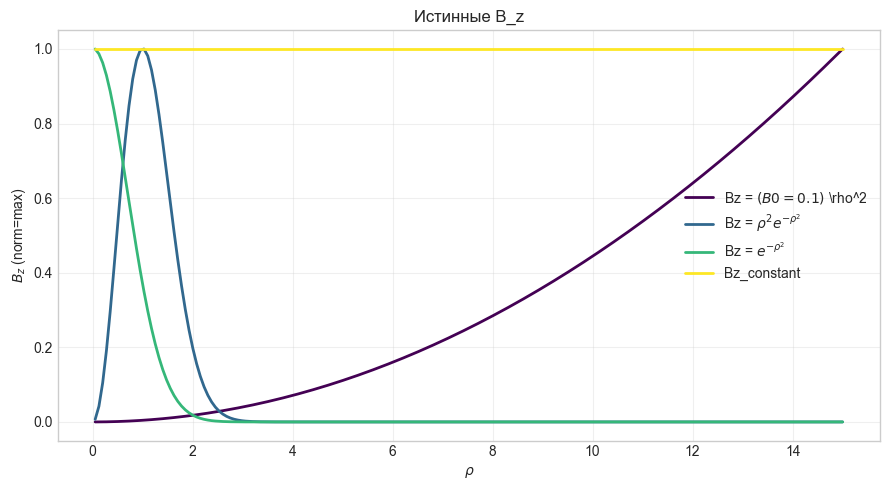

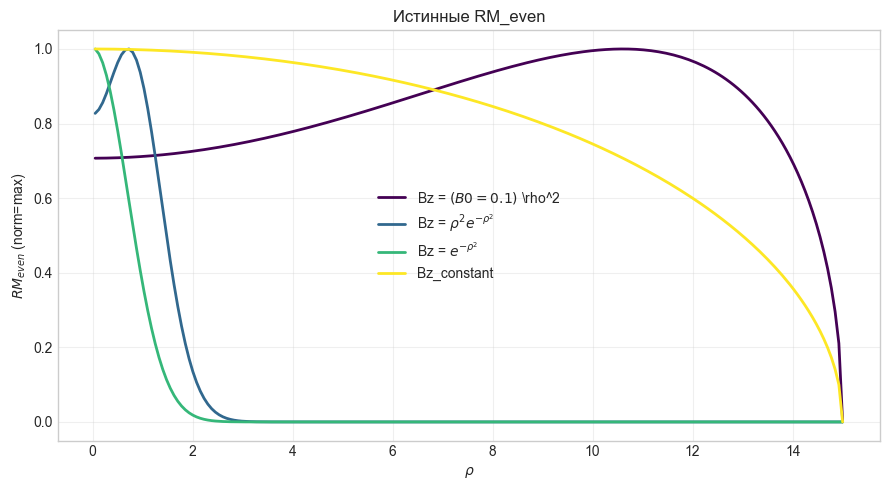

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


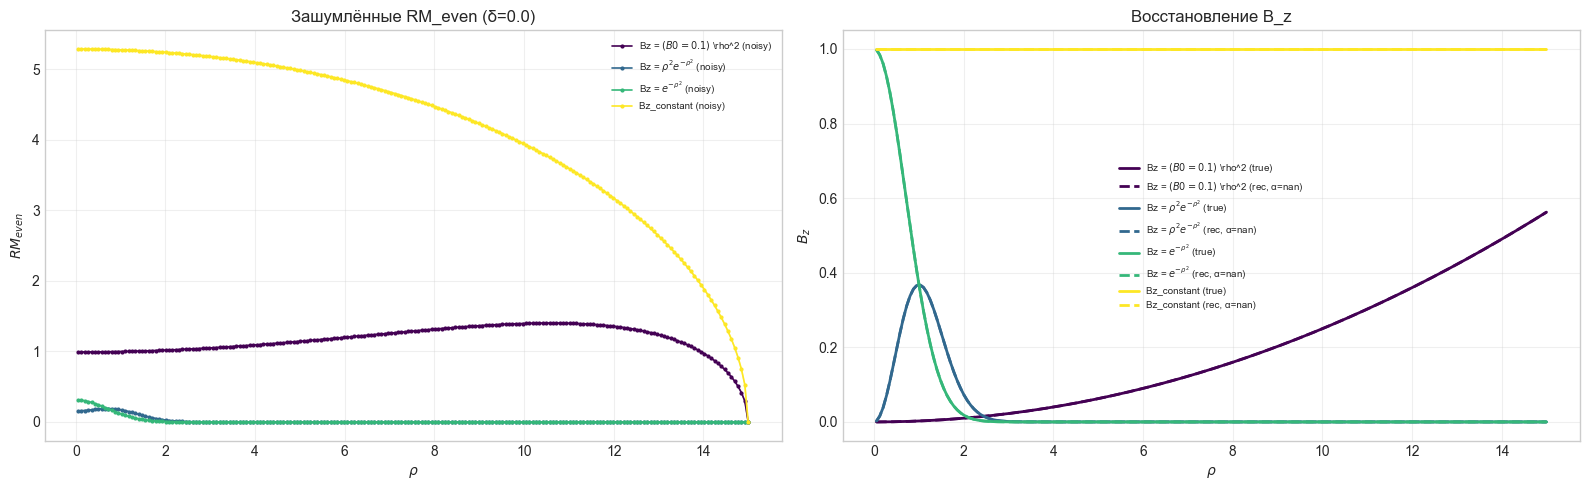

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


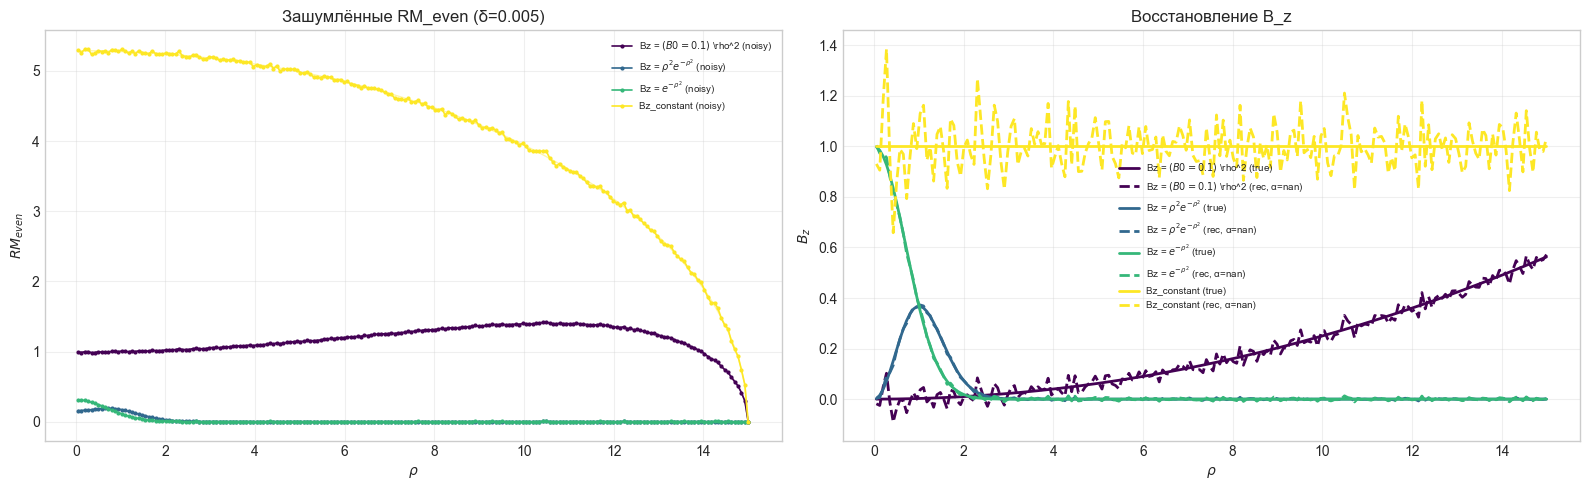

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


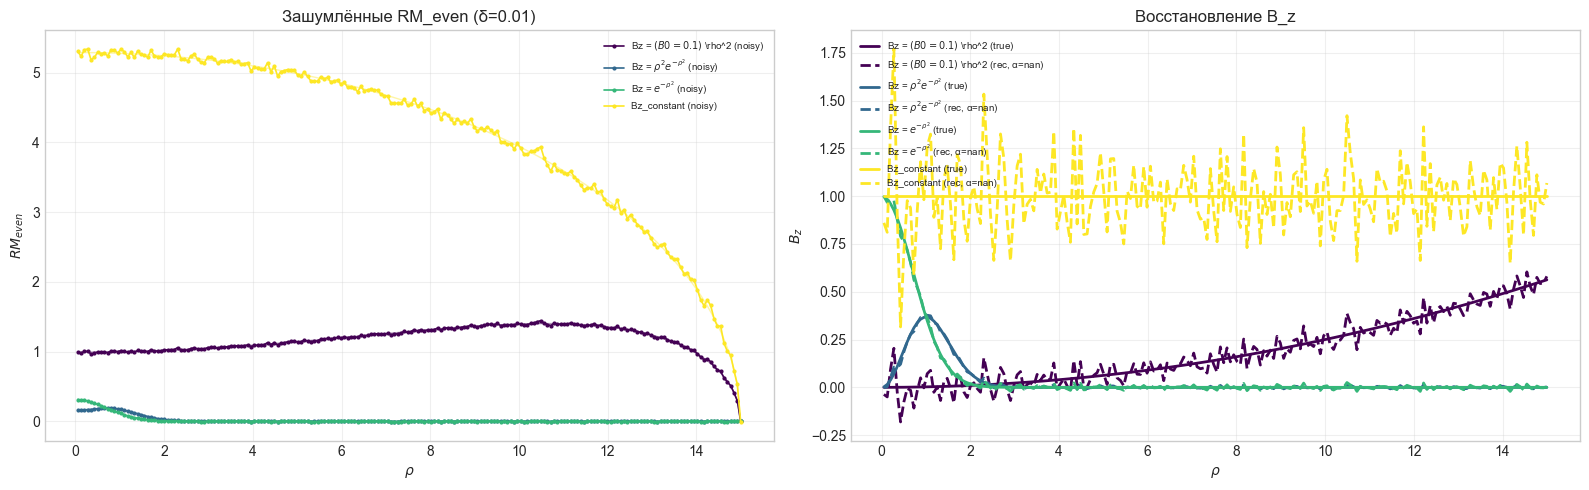

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


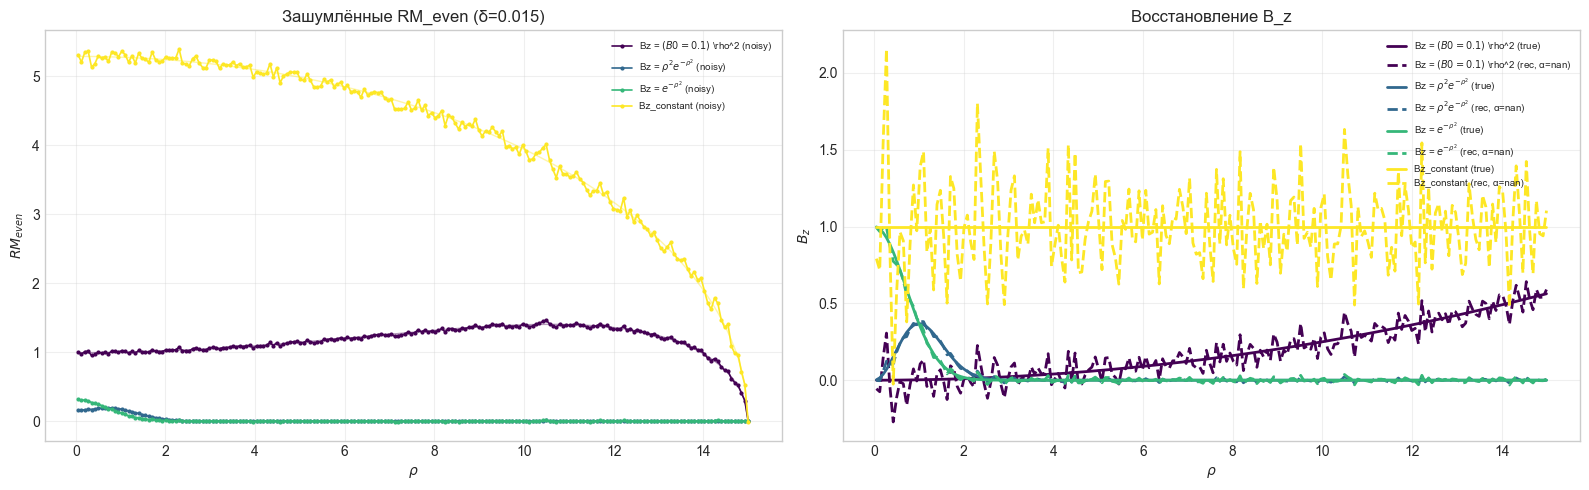

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


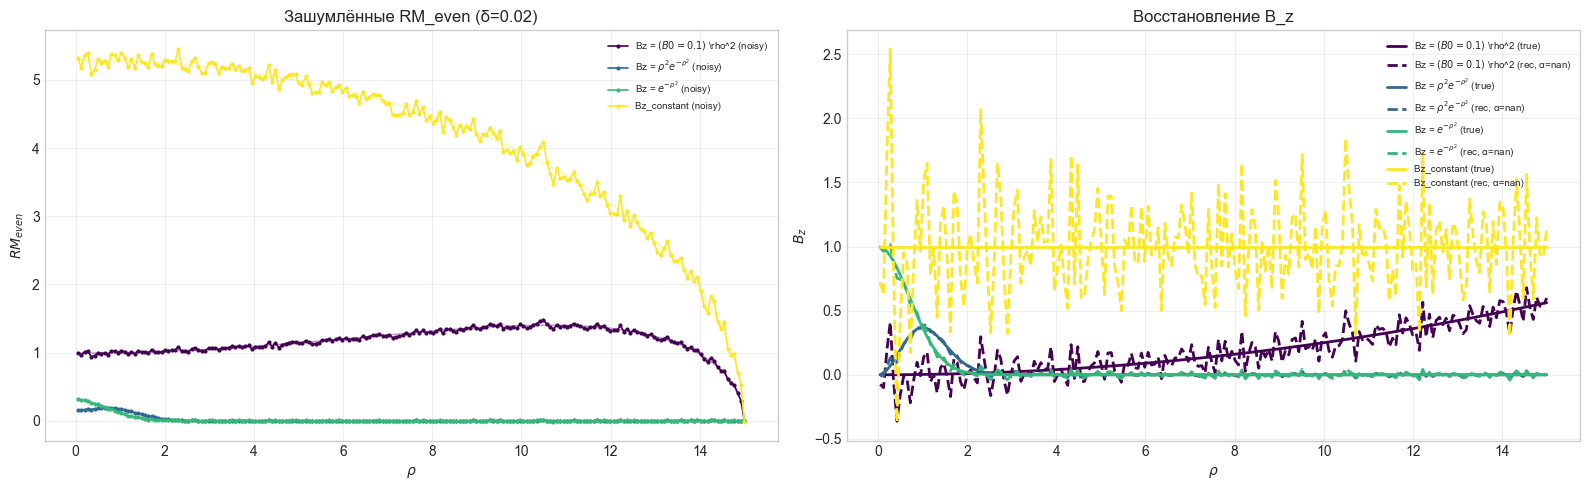

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


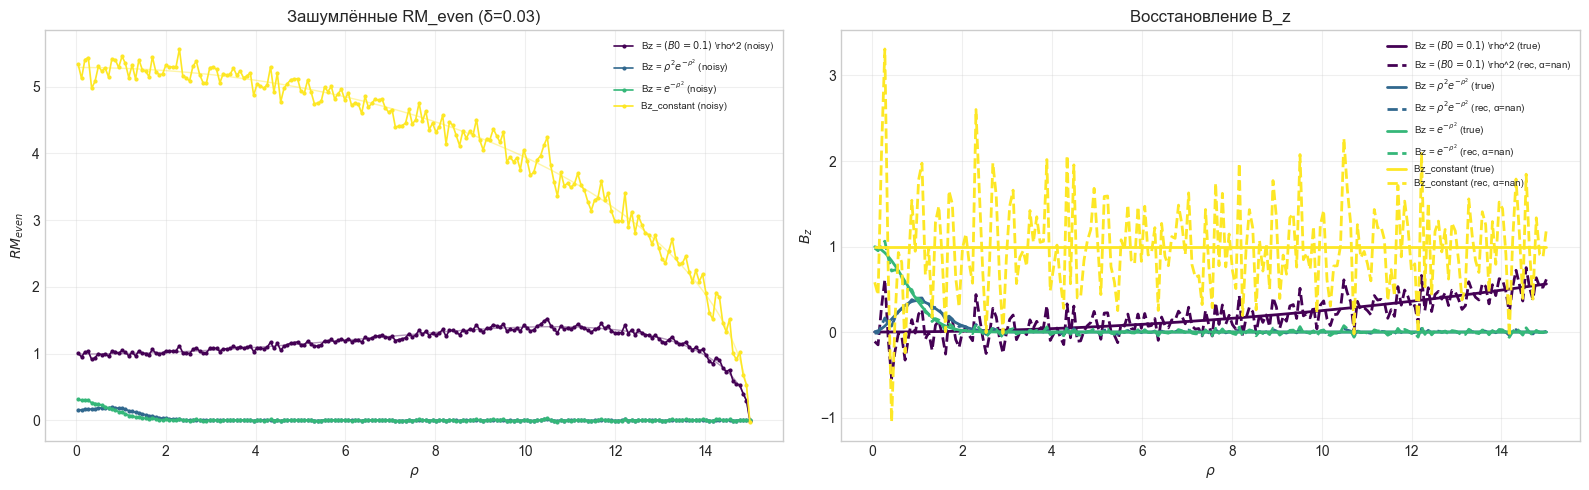

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


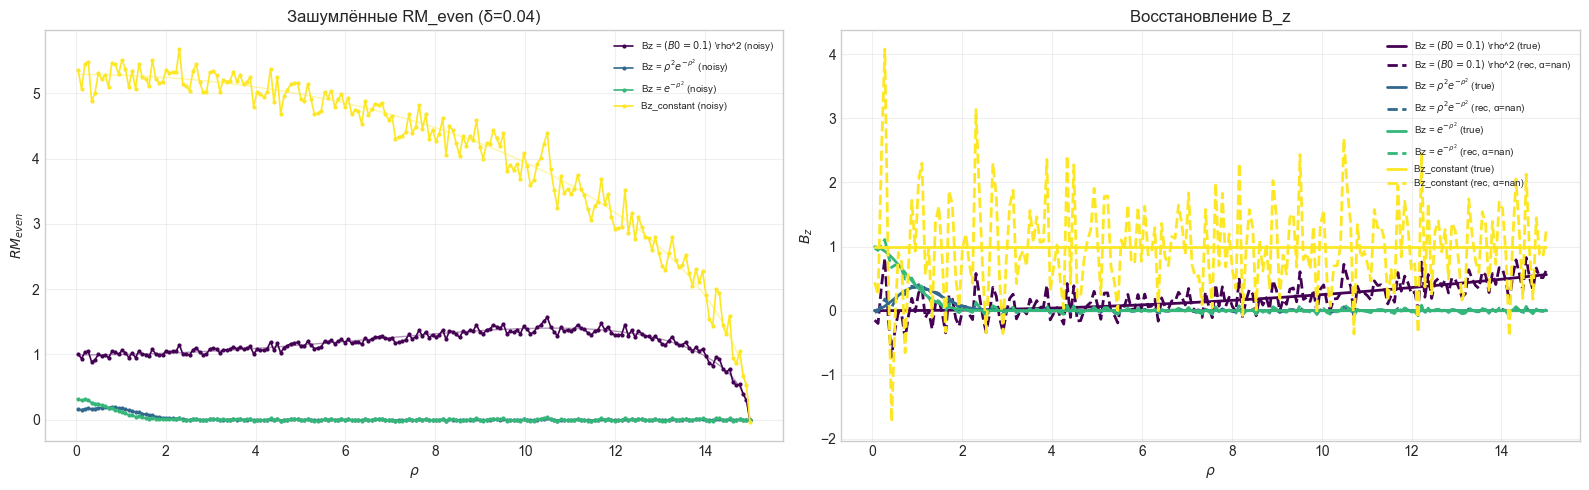

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


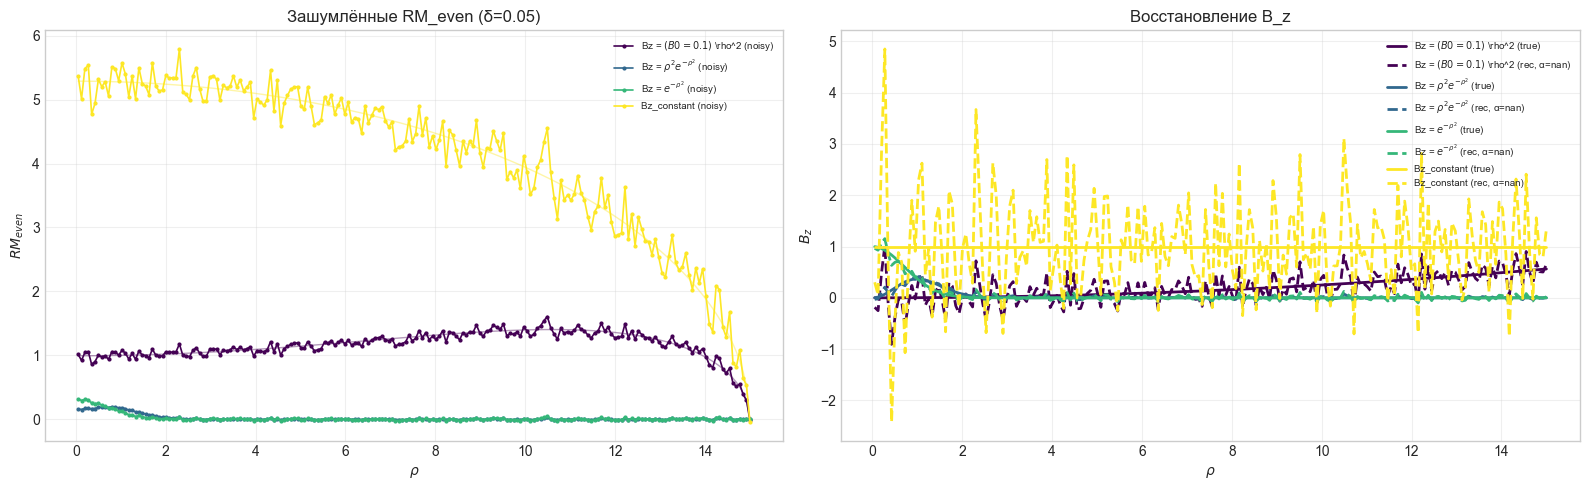

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


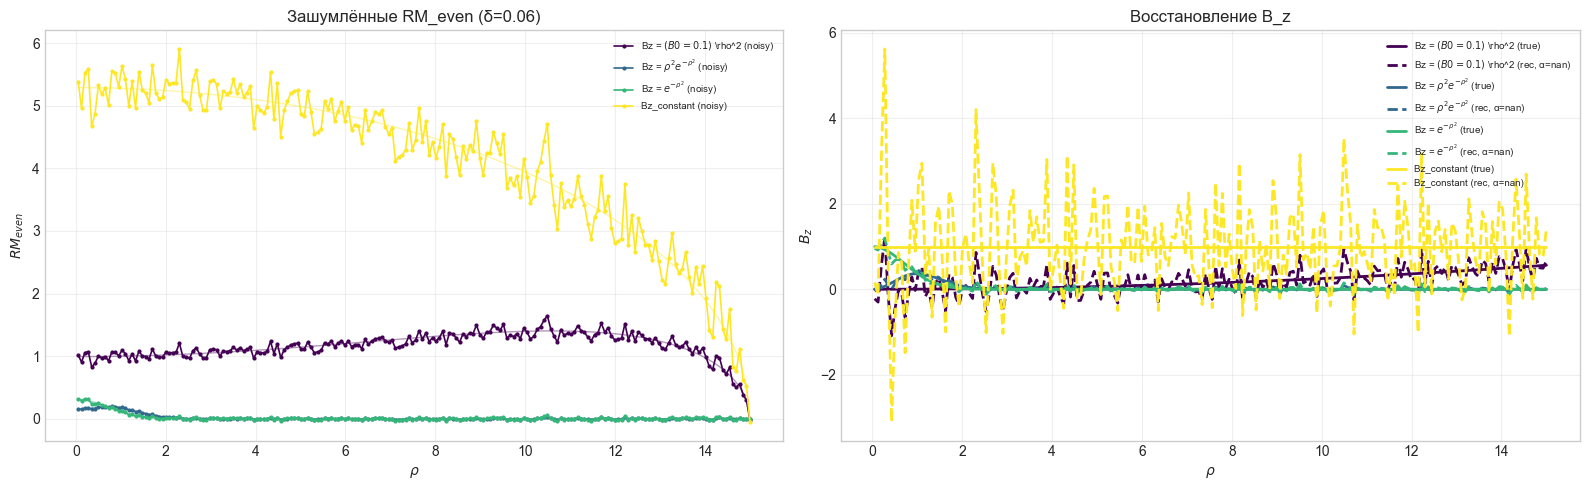

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


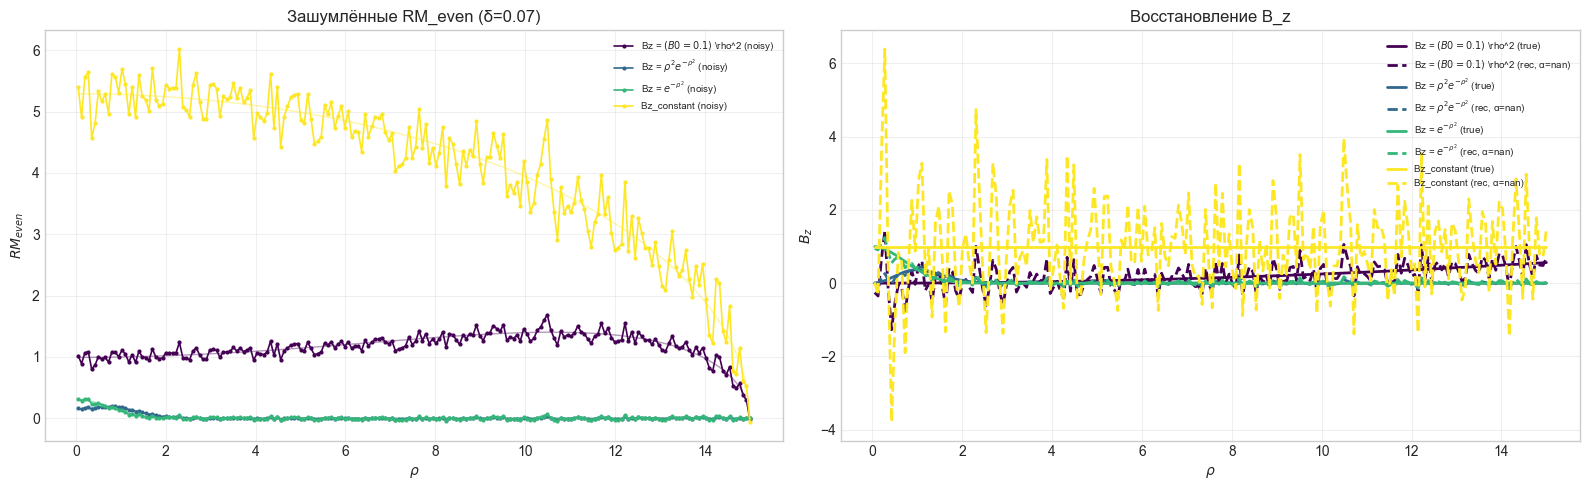

Загружено запусков: ['Bz = $(B0=0.1)$ \\rho^2', 'Bz = $\\rho^2 e^{-\\rho^2}$', 'Bz = $e^{-\\rho^2}$', 'Bz_constant']


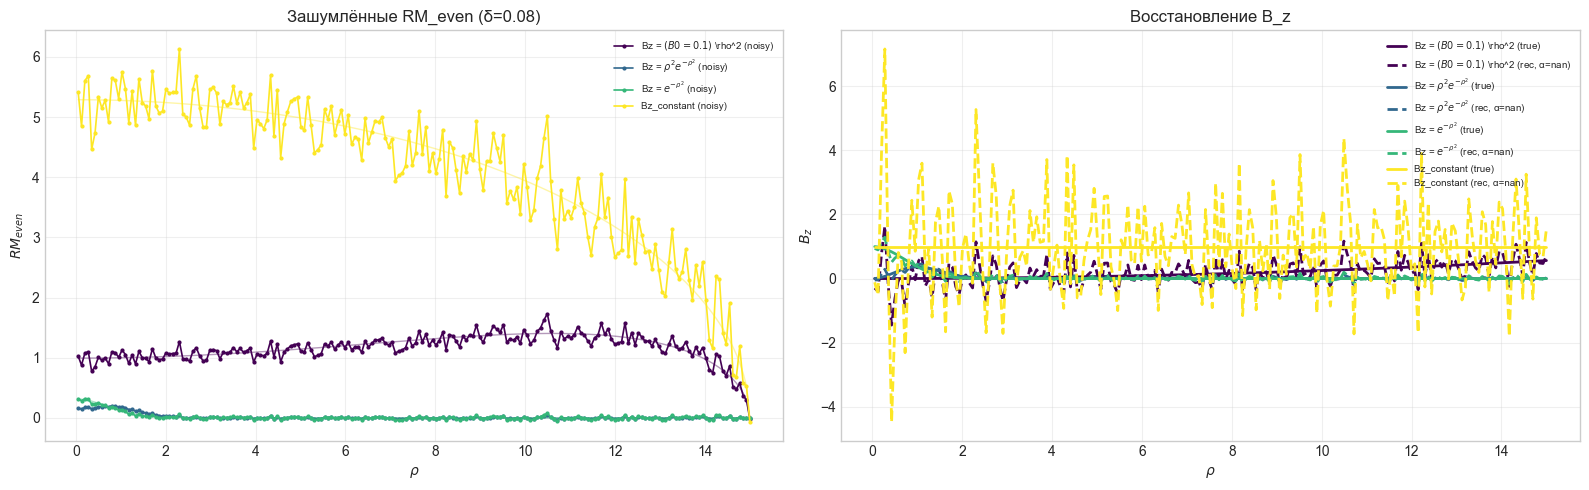

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


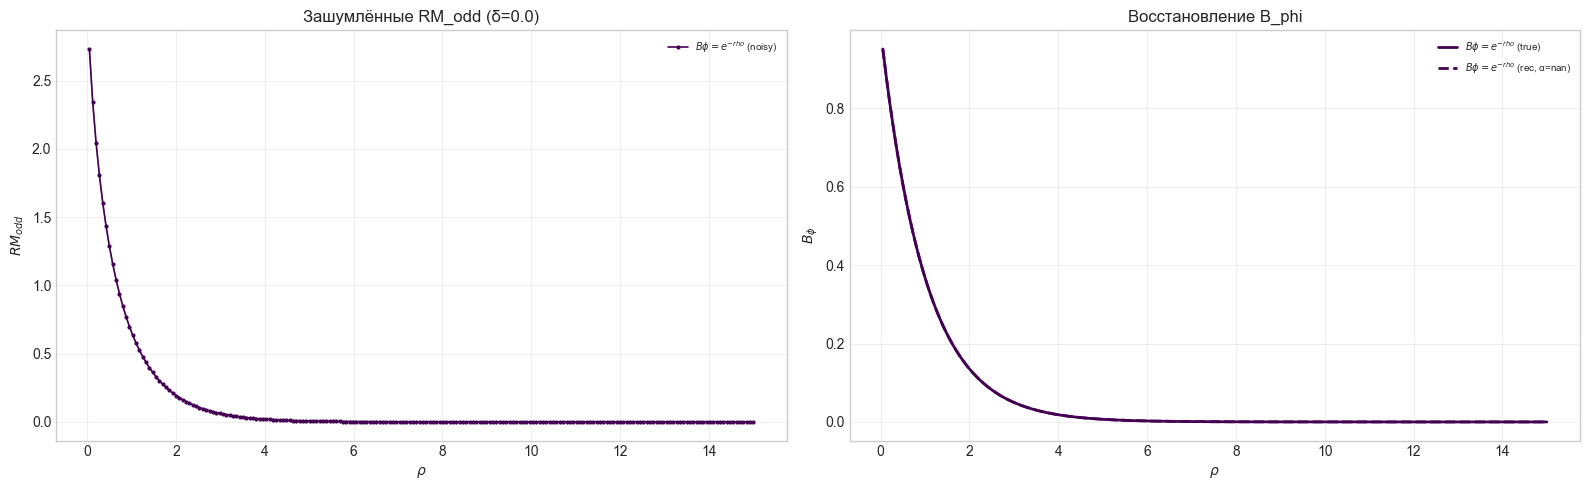

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


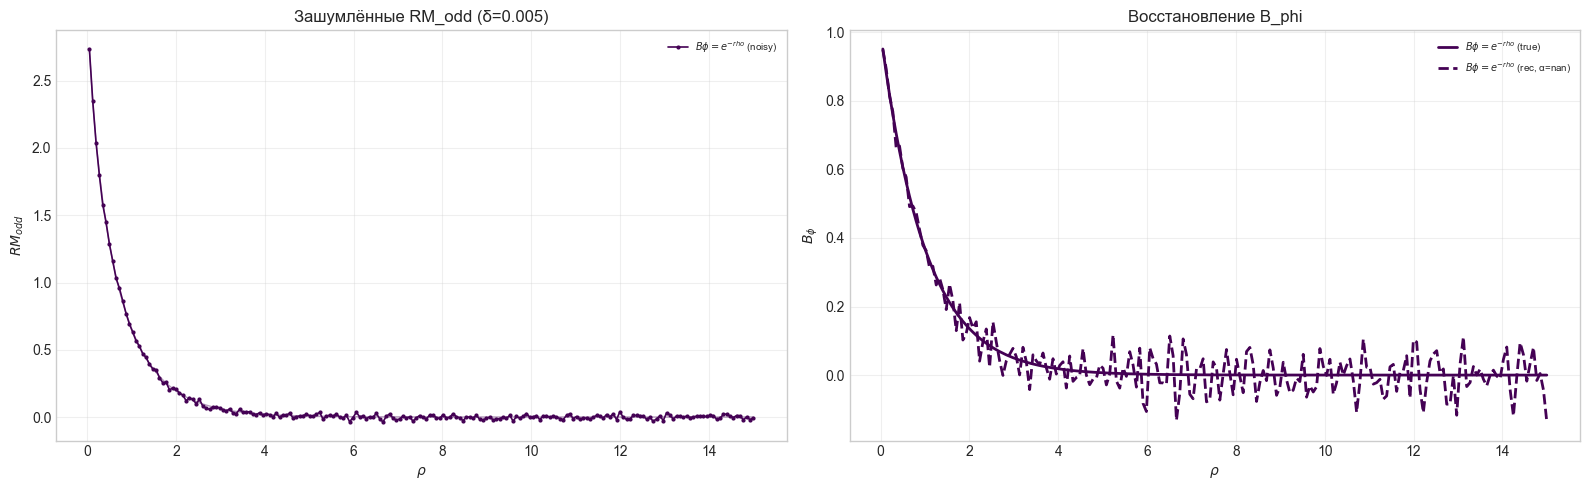

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


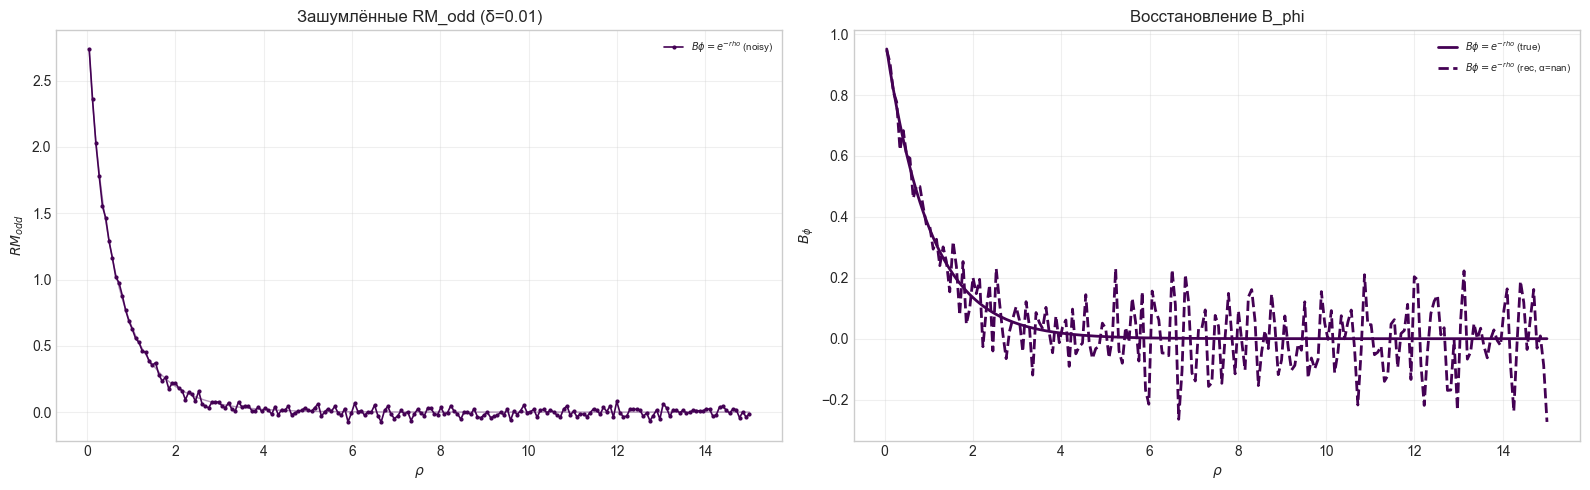

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


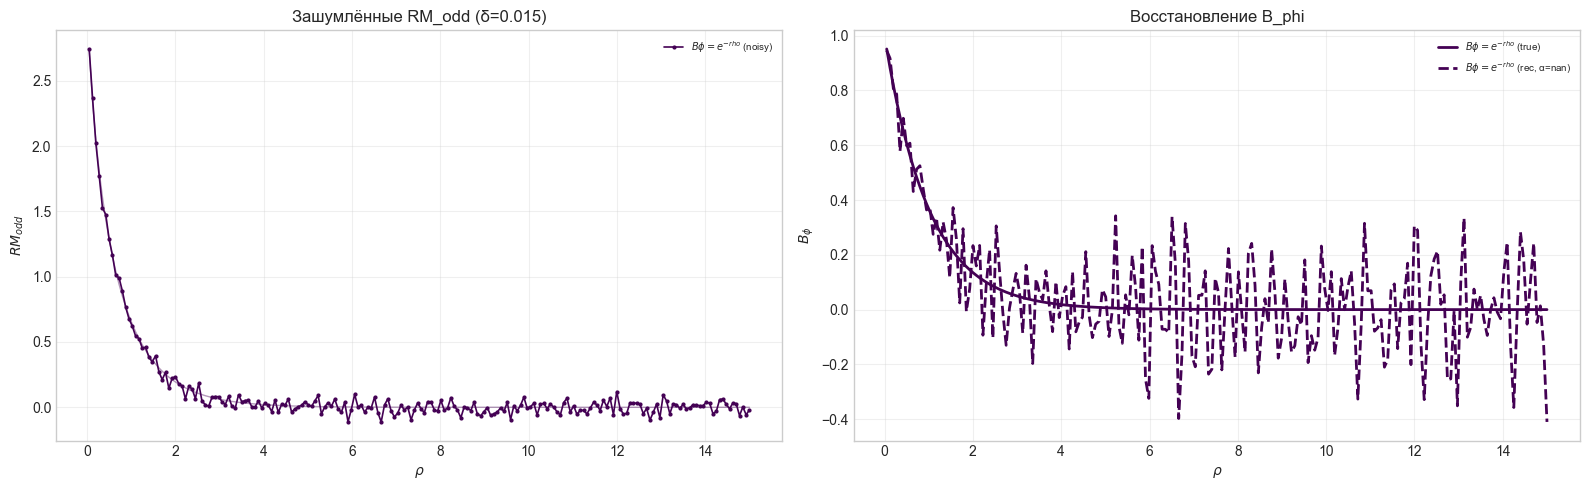

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


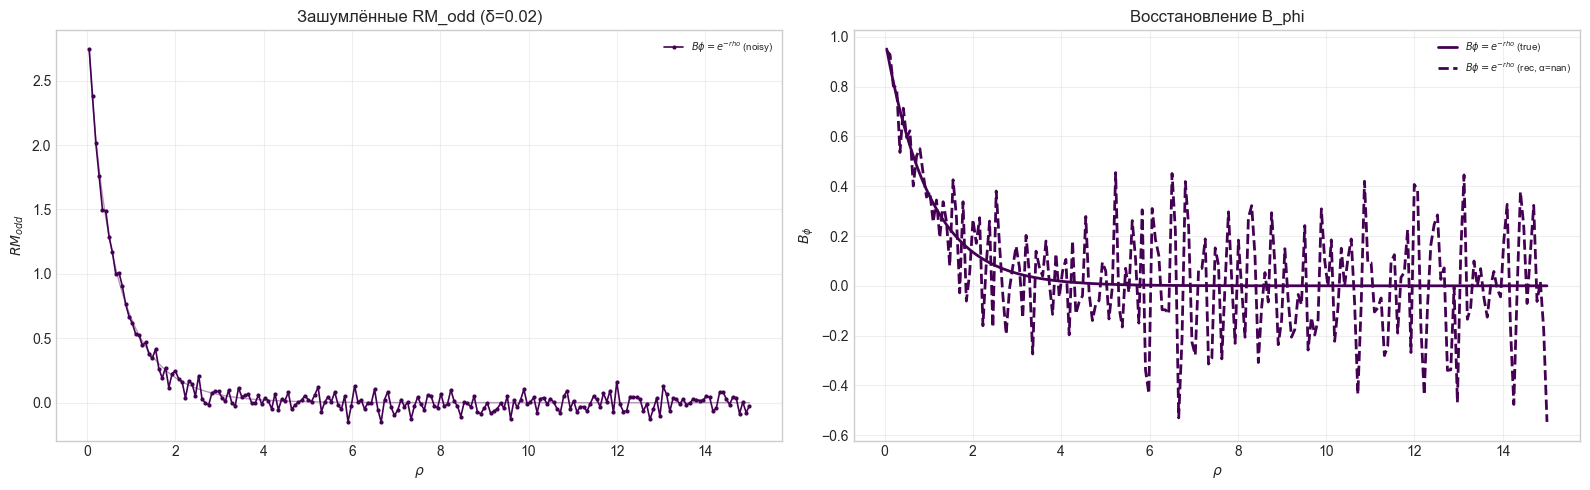

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


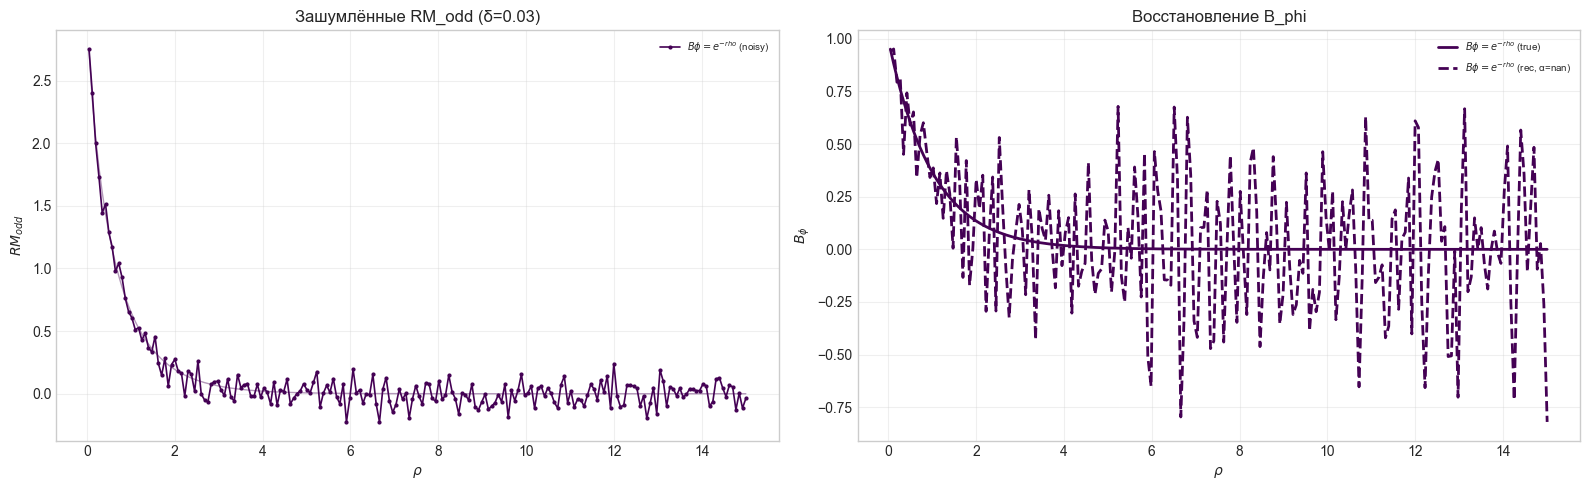

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


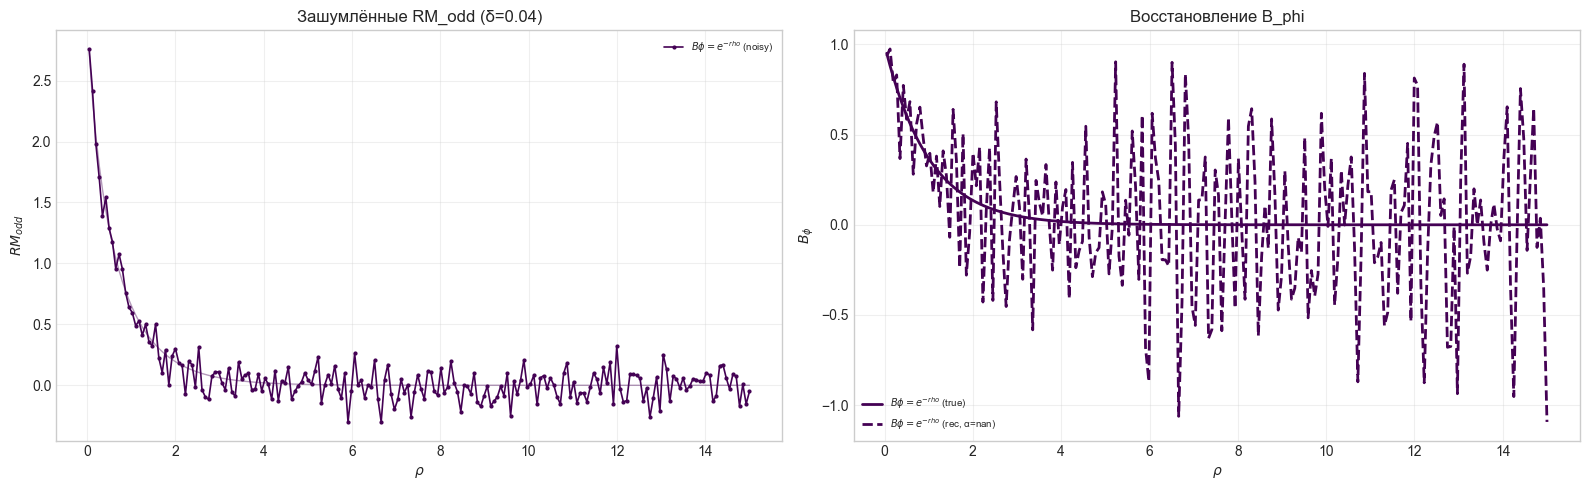

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


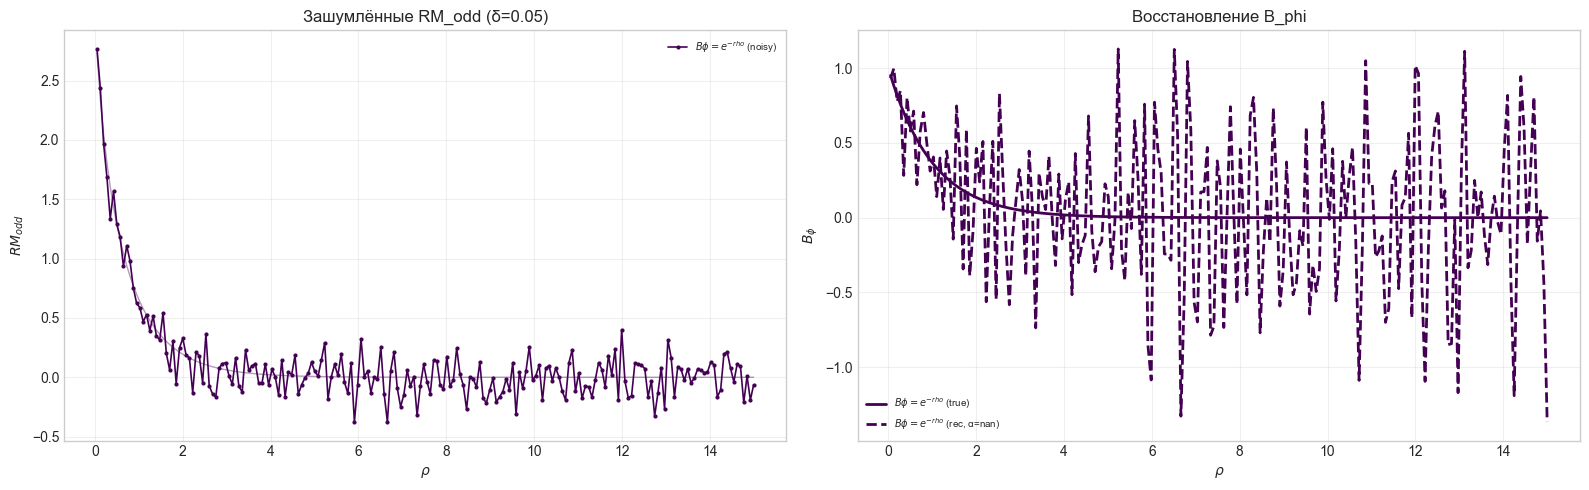

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


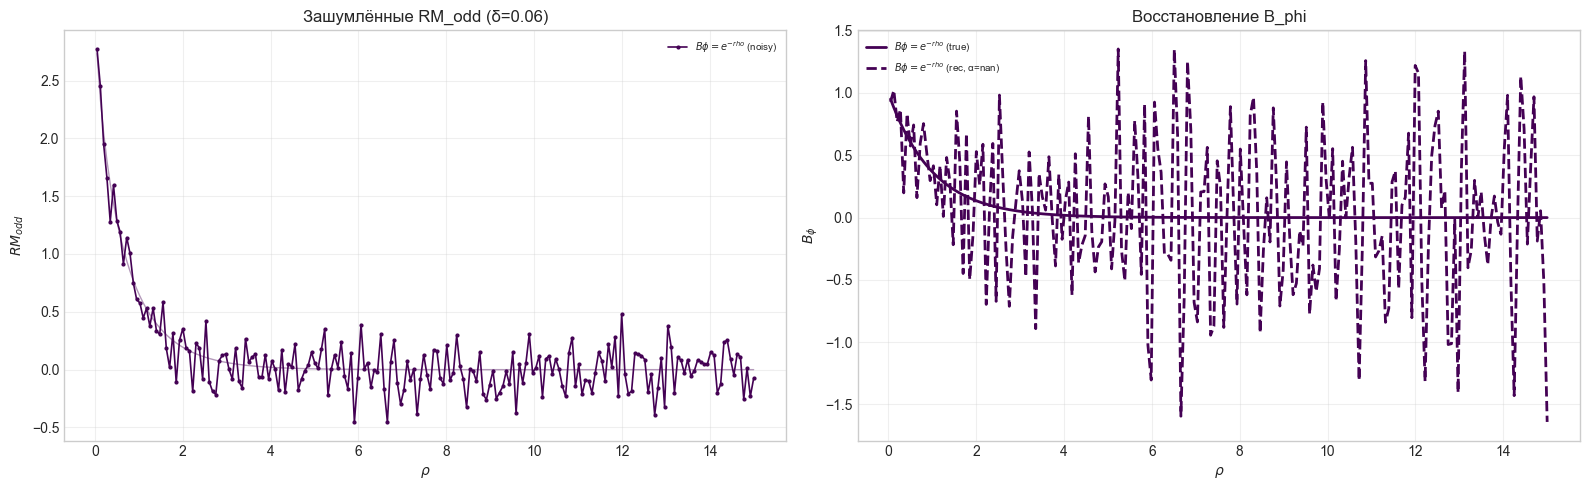

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


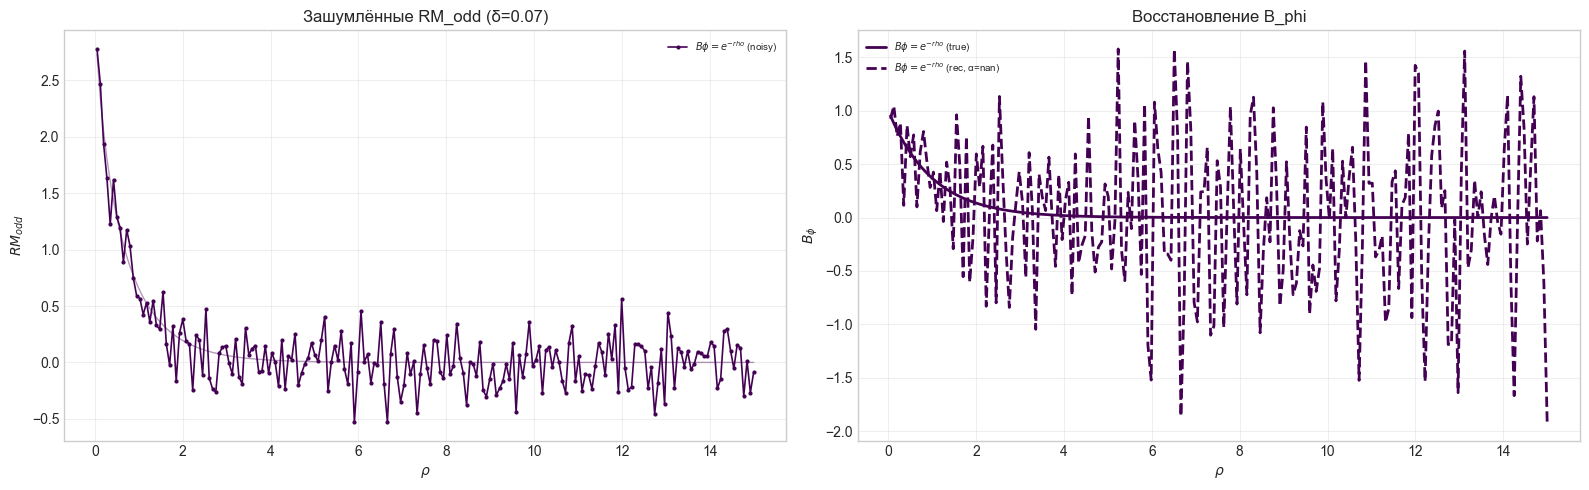

Загружено запусков (B_phi): ['$B\\phi = e^{-rho}$']


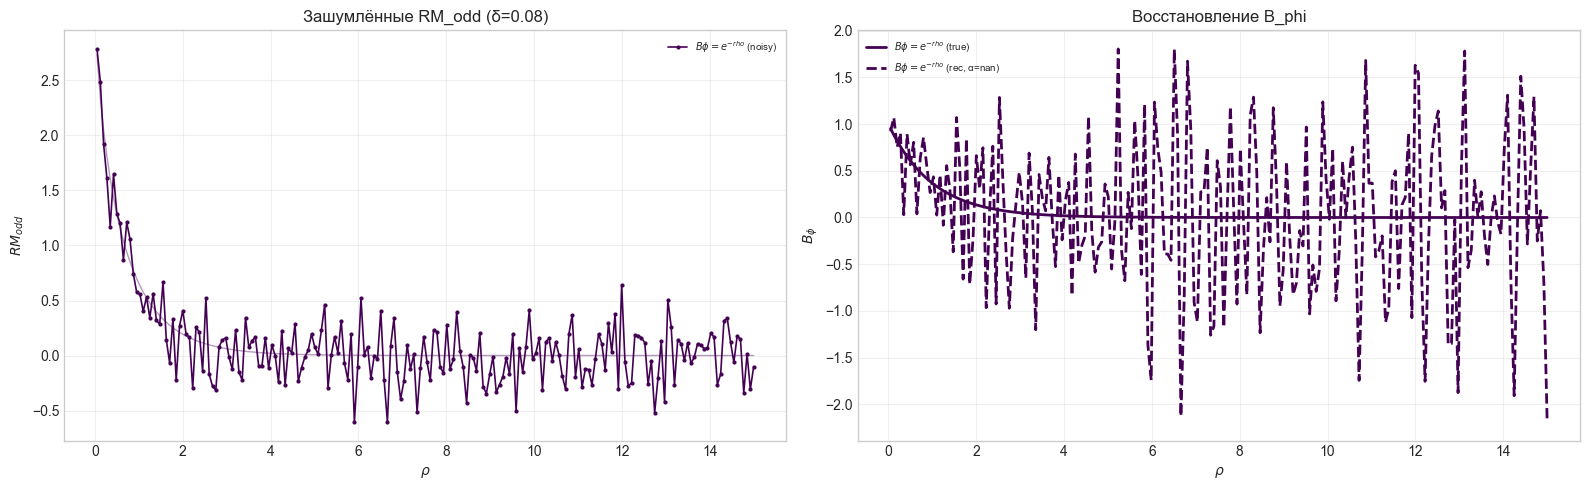

In [12]:
# ==============================================================================
# ЧТЕНИЕ ВСЕХ ЗАПУСКОВ И СВОДНЫЕ ГРАФИКИ
# ==============================================================================
 
FILENAME = _fname(deltas[0], REG_KIND)
rho, runs = load_runs(FILENAME)

# 1) Все истинные B_z на одном графике
plot_all_true_fields(rho, runs, field_key='B_z_true',
                        ylabel=r'$B_z$',
                        title="Истинные B_z",
                        norm = "max")

# 2) Все RM_even (истинные) на одном графике
plot_all_rm(rho, runs, rm_key='RM_even_true',
            ylabel=r'$RM_{even}$',
            title="Истинные RM_even",
            norm = "max")

for delta_tmp in deltas:
        FILENAME = _fname(delta_tmp,  REG_KIND)
        
        rho, runs = load_runs(FILENAME)
        print(f"Загружено запусков: {list(runs.keys())}")
        
        TYPE_NORM = None # None, "max"
        
        # Создаем фигуру с двумя графиками в строку
        fig, axes = plt.subplots(1, 2, figsize=(16, 5))
        
        # 3) Все зашумлённые RM_even на одном графике
        plot_all_rm_noisy(rho, runs,
                        rm_noisy_key='RM_even_noisy',
                        rm_true_key='RM_even_true',
                        ylabel=r'$RM_{even}$',
                        title=f"Зашумлённые RM_even (δ={delta_tmp})",
                        norm = TYPE_NORM,
                        ax=axes[0],
                        legend=True)

        # 4) Все восстановленные B_z + истинные — на одном графике
        plot_all_recovered_fields(rho, runs,
                                true_key='B_z_true',
                                rec_key='B_z_rec',
                                ylabel=r'$B_z$',
                                title="Восстановление B_z",
                                norm = TYPE_NORM,
                                ax=axes[1],
                                legend=True)
        
        # Настраиваем отступы, чтобы ничего не наезжало друг на друга
        plt.tight_layout()
        plt.show()

for delta_tmp in deltas:
    FILENAME = _fname(delta_tmp, REG_KIND, 'Bphi', '_(rho)_(var_B)')
    
    # Проверяем, существует ли файл вообще
    if not os.path.exists(FILENAME):
        print(f"⚠️ Файл {FILENAME} не найден, пропускаем.")
        continue
        
    rho, runs = load_runs(FILENAME)
    print(f"Загружено запусков (B_phi): {list(runs.keys())}")

    # --- Графики для B_phi ---
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    try:
        plot_all_rm_noisy(rho, runs,
                        rm_noisy_key='RM_odd_noisy', 
                        rm_true_key='RM_odd_true',
                        ylabel=r'$RM_{odd}$', 
                        title=f"Зашумлённые RM_odd (δ={delta_tmp})",
                        norm=None, 
                        ax=axes[0], legend=True)
    except Exception as e:
        print(f"Ошибка при построении RM_odd: {e}")
        axes[0].set_title("Нет данных для RM_odd")
        
    try:
        plot_all_recovered_fields(rho, runs,
                                true_key='B_phi_true', 
                                rec_key='B_phi_rec',
                                ylabel=r'$B_\phi$', 
                                title="Восстановление B_phi",
                                norm=None, 
                                ax=axes[1], legend=True)
    except Exception as e:
        print(f"Ошибка при построении B_phi: {e}")
        axes[1].set_title("Нет данных для B_phi")
    
    plt.tight_layout()
    plt.show()


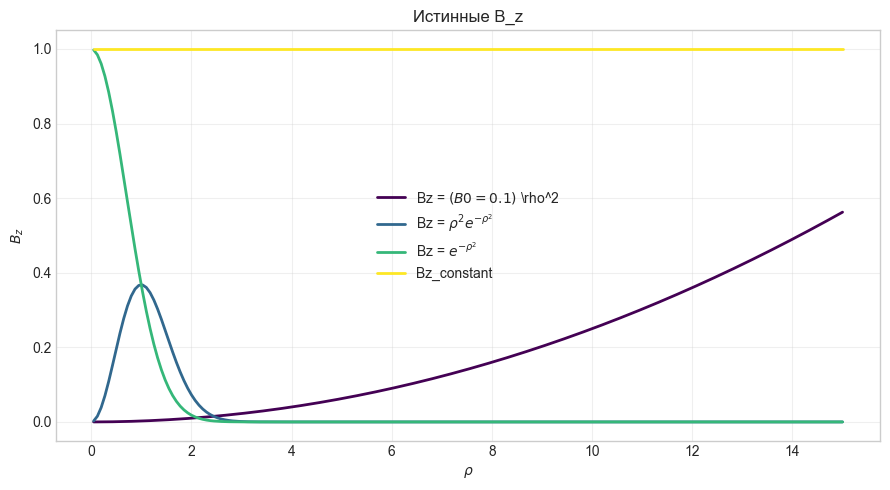

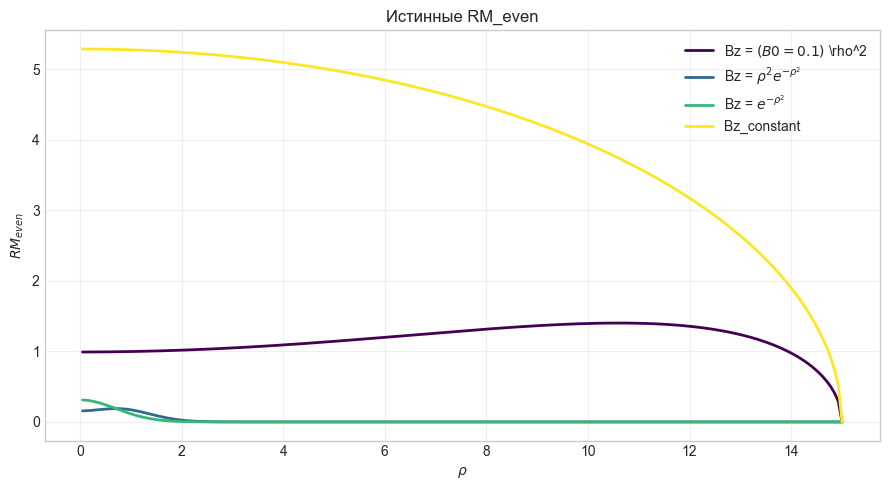

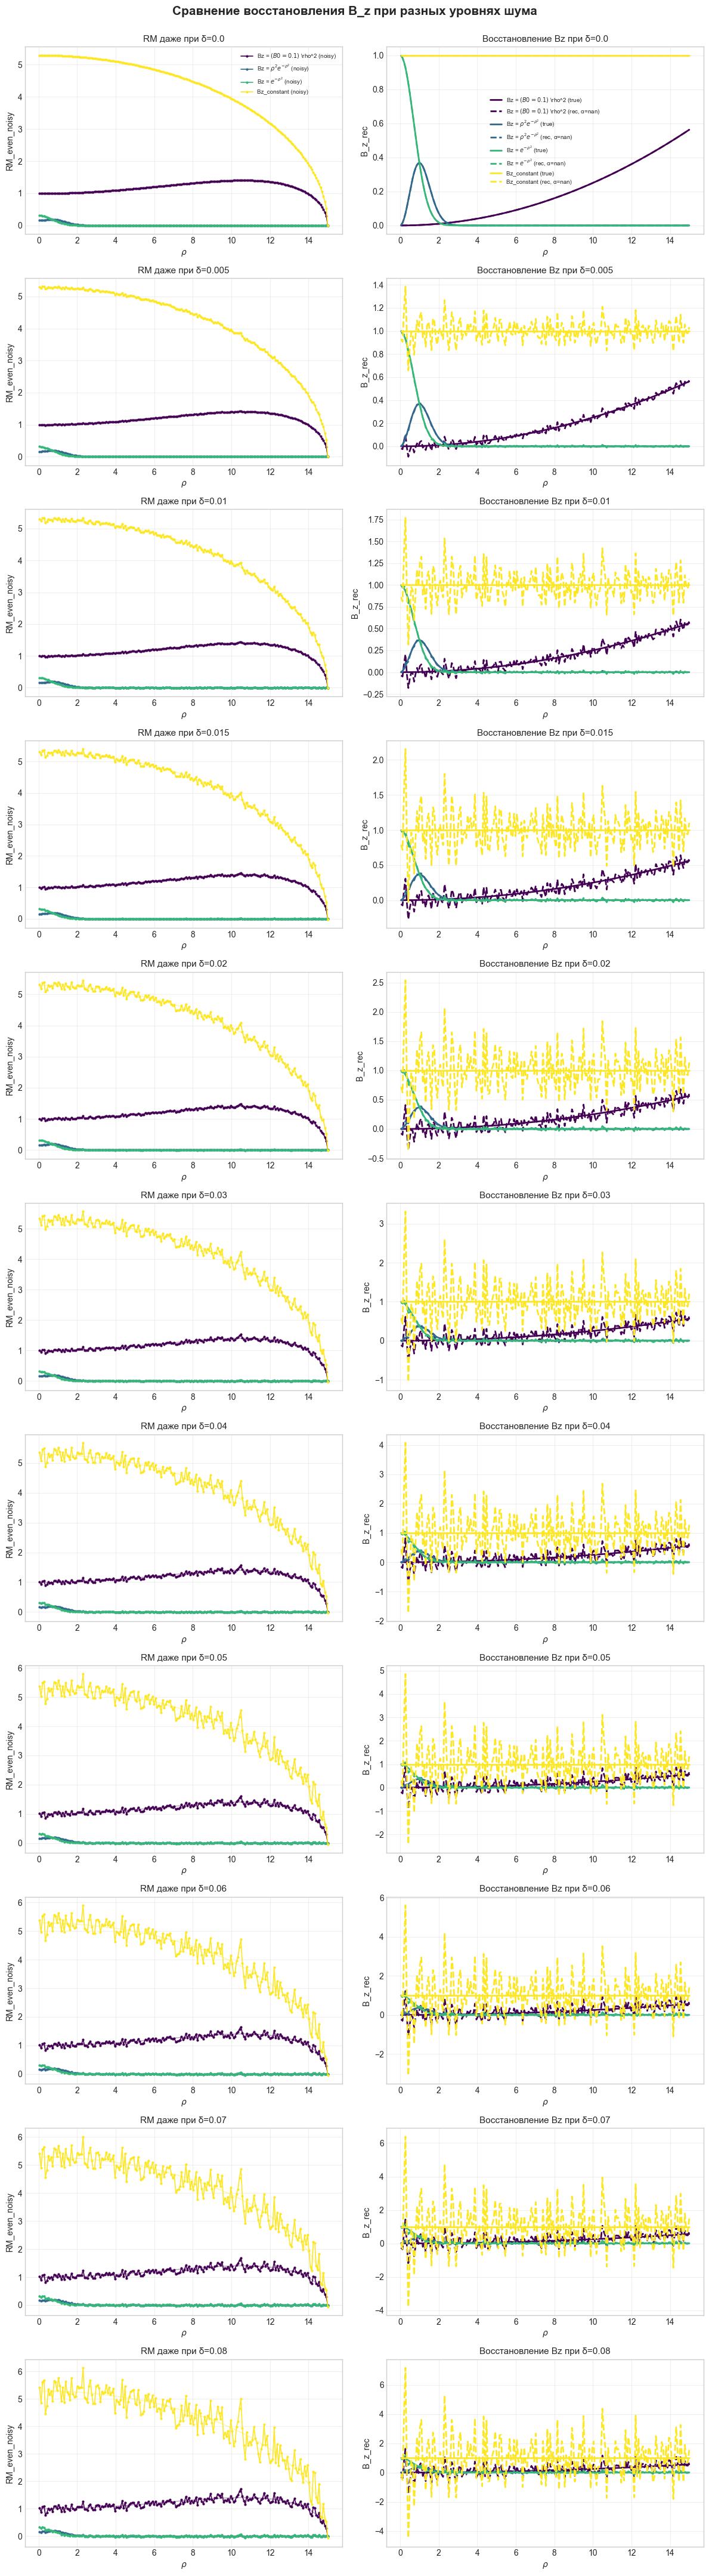

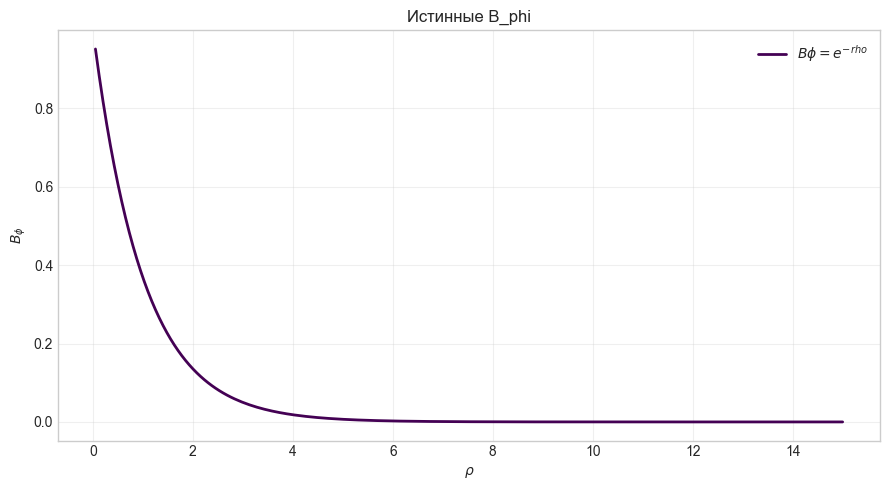

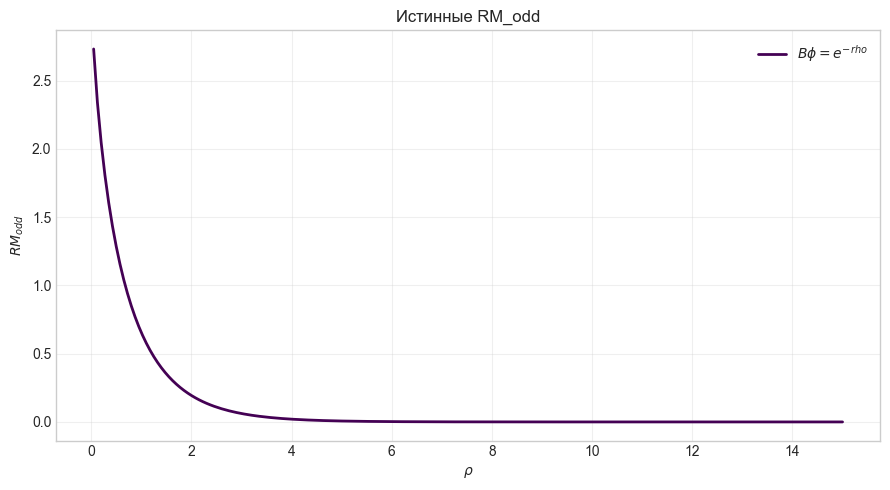

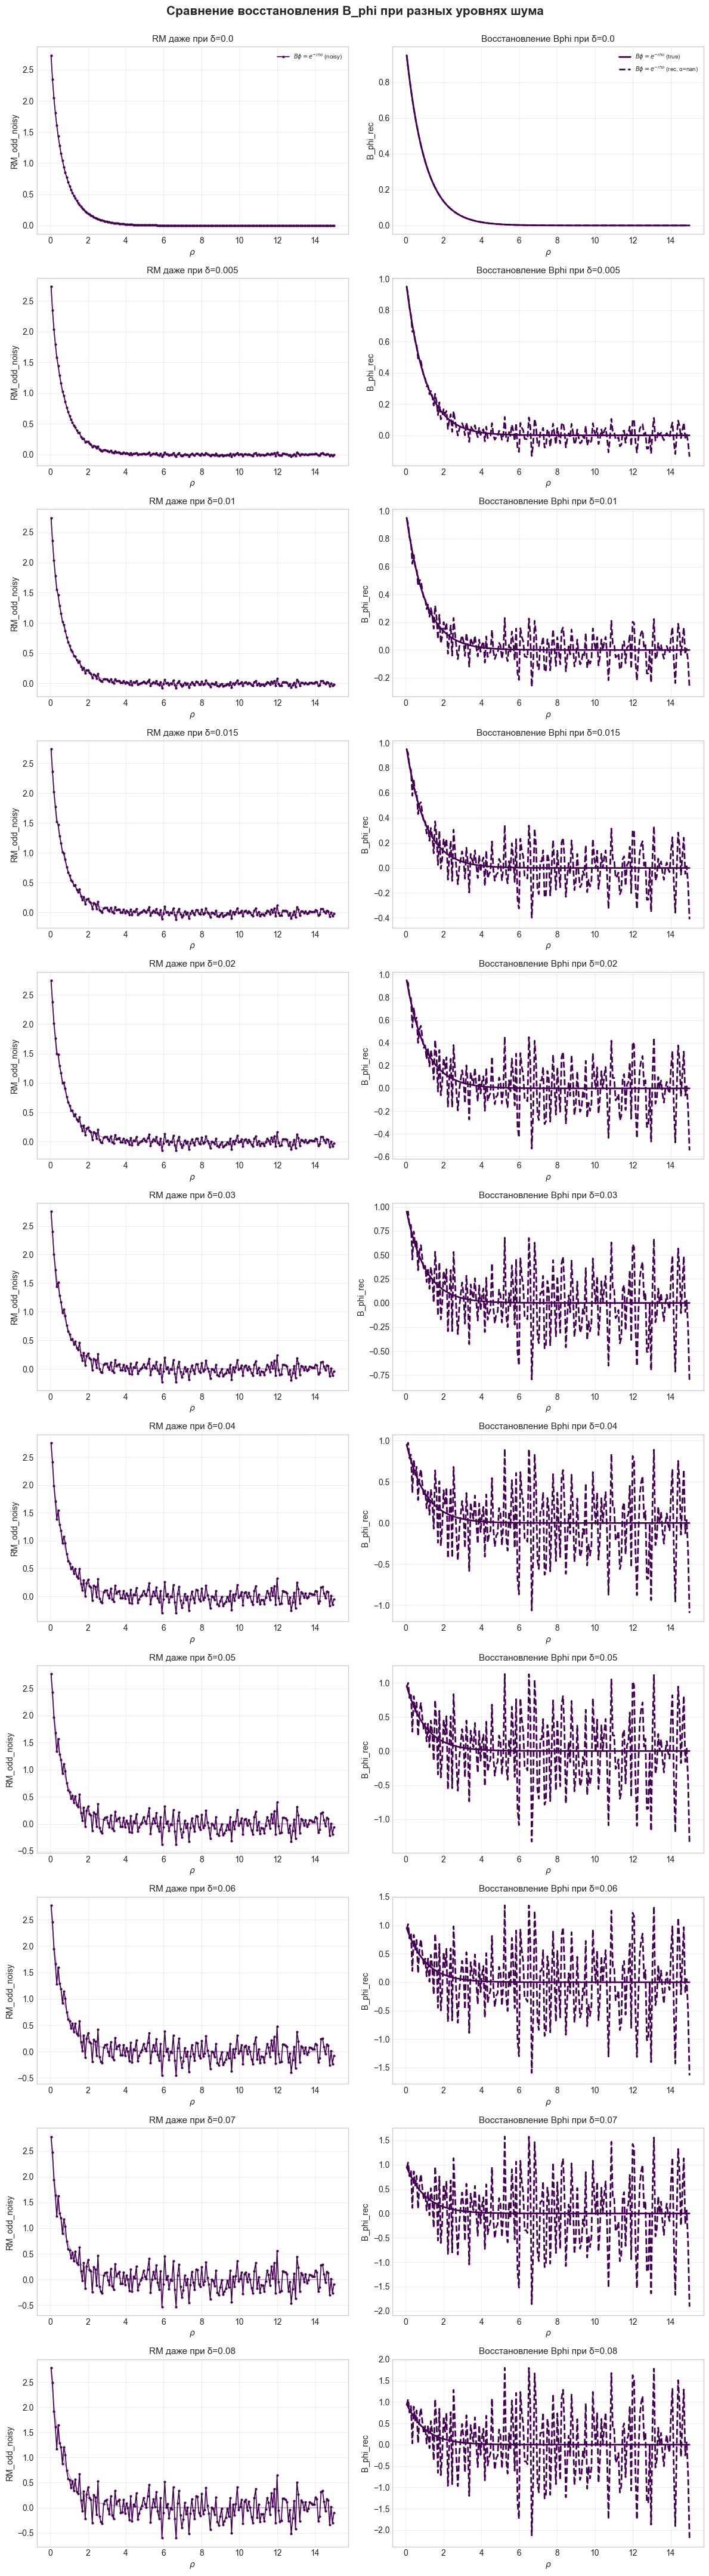

In [14]:
from methods import plot_noise_sweep_grid
import os

# ==============================================================================
# 1. СВОДНАЯ СЕТКА ДЛЯ B_z
# ==============================================================================
csv_paths_bz = {d: _fname(d, REG_KIND) for d in deltas}

rho, runs_bz = load_runs(csv_paths_bz[deltas[0]])

TYPE_NORM = None
# 1) Все истинные B_z на одном графике
plot_all_true_fields(rho, runs_bz, field_key='B_z_true',
                     ylabel=r'$B_z$',
                     title="Истинные B_z",
                     norm=TYPE_NORM)

# 2) Все RM_even (истинные) на одном графике
plot_all_rm(rho, runs_bz, rm_key='RM_even_true',
            ylabel=r'$RM_{even}$',
            title="Истинные RM_even",
            norm=TYPE_NORM)

# Сводная сетка для B_z
plot_noise_sweep_grid(
    csv_paths_bz,
    deltas=sorted(csv_paths_bz.keys()),
    norm=TYPE_NORM,
    title="Сравнение восстановления B_z при разных уровнях шума",
    rm_noisy_key='RM_even_noisy',
    rm_true_key='RM_even_true',
    rec_key='B_z_rec',
    rec_true_key='B_z_true',
)


# ==============================================================================
# 2. СВОДНАЯ СЕТКА ДЛЯ B_phi
# ==============================================================================
csv_paths_bphi = {d: _fname(d, REG_KIND, 'Bphi', '_(rho)_(var_B)') for d in deltas}
TYPE_NORM = None
if os.path.exists(csv_paths_bphi[deltas[0]]):
    rho, runs_bphi = load_runs(csv_paths_bphi[deltas[0]])

    # 1) Все истинные B_phi на одном графике
    plot_all_true_fields(rho, runs_bphi, field_key='B_phi_true',
                         ylabel=r'$B_\phi$',
                         title="Истинные B_phi",
                         norm=TYPE_NORM)

    # 2) Все RM_odd (истинные) на одном графике
    plot_all_rm(rho, runs_bphi, rm_key='RM_odd_true',
                ylabel=r'$RM_{odd}$',
                title="Истинные RM_odd",
                norm=TYPE_NORM)

    # Сводная сетка для B_phi
    plot_noise_sweep_grid(
        csv_paths_bphi,
        deltas=sorted(csv_paths_bphi.keys()),
        norm=TYPE_NORM,
        title="Сравнение восстановления B_phi при разных уровнях шума",
        rm_noisy_key='RM_odd_noisy',
        rm_true_key='RM_odd_true',
        rec_key='B_phi_rec',
        rec_true_key='B_phi_true',  
        type_B = 'Bphi'
    )
else:
    print(f"⚠️ Файлы для B_phi не найдены. Пропускаем.")


АНАЛИЗ ОШИБОК ДЛЯ B_z


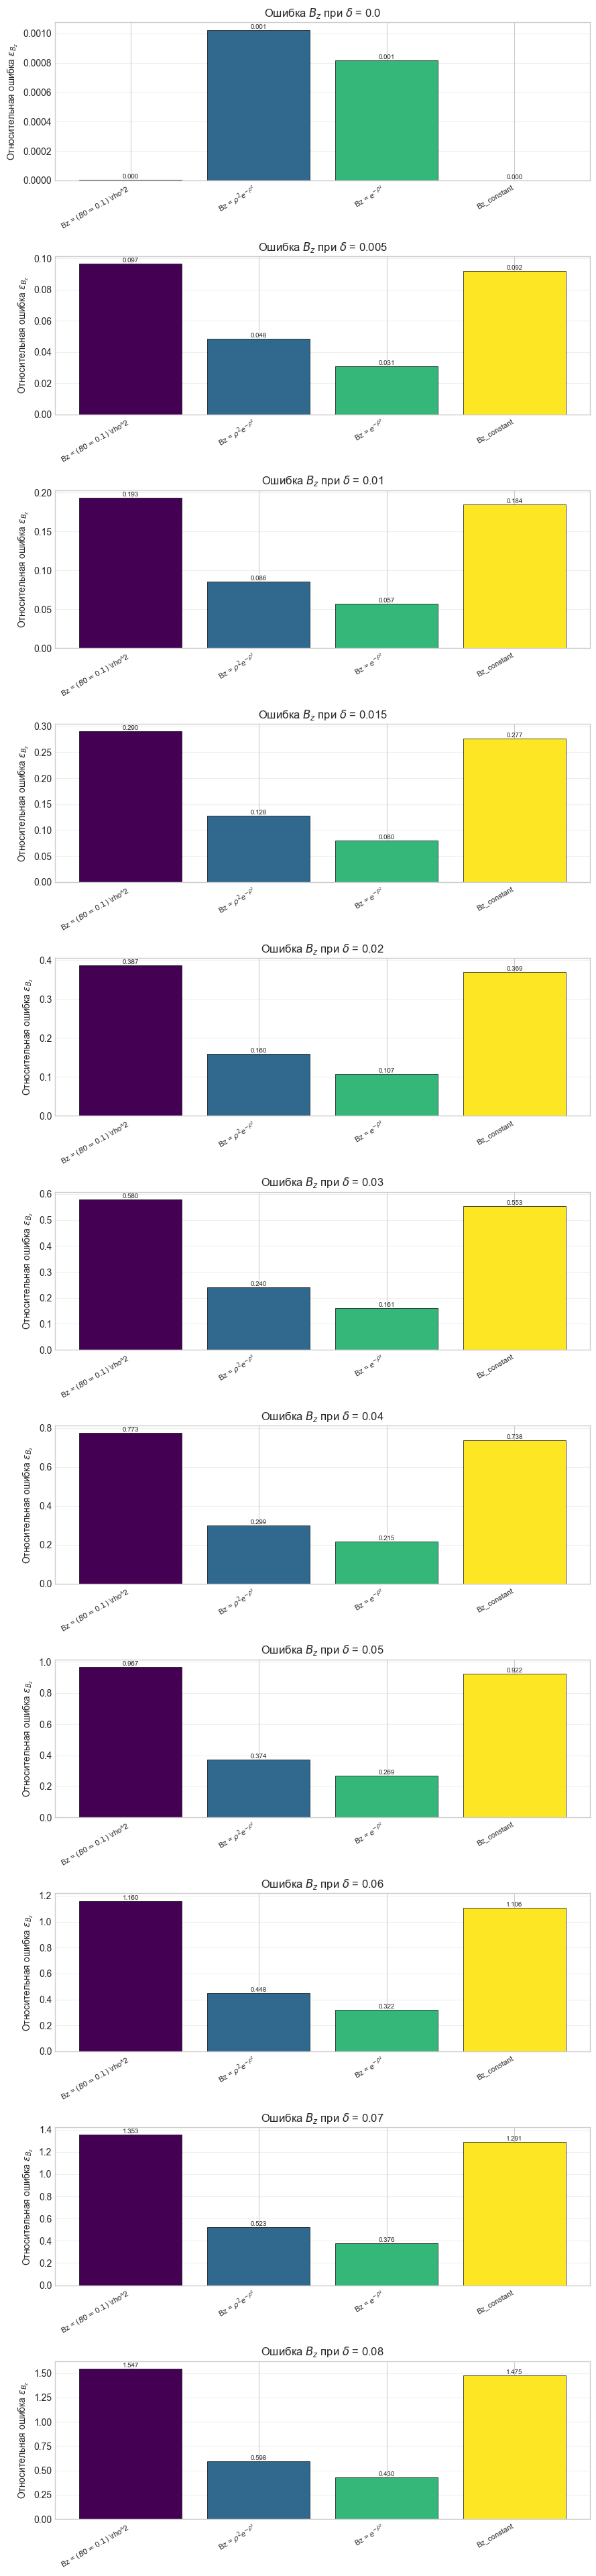

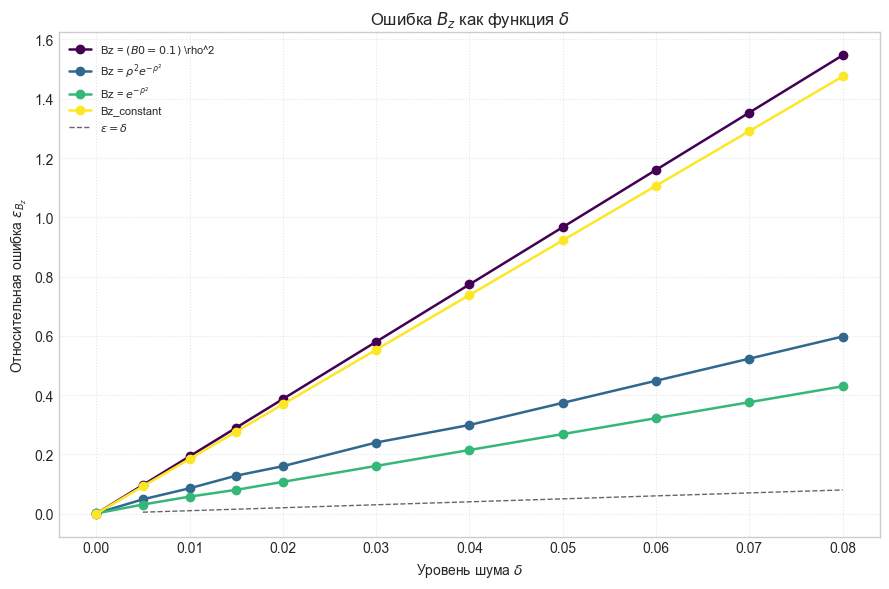

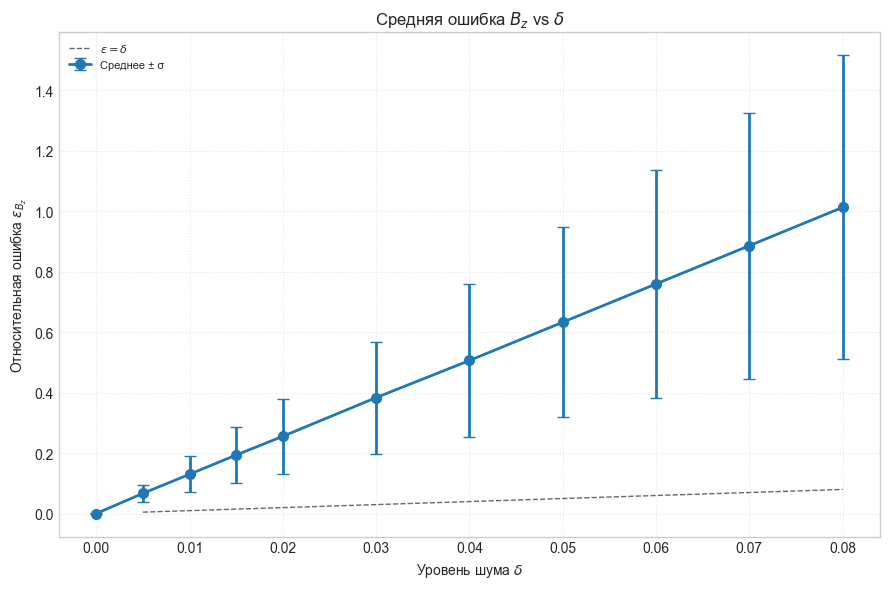


АНАЛИЗ ОШИБОК ДЛЯ B_phi


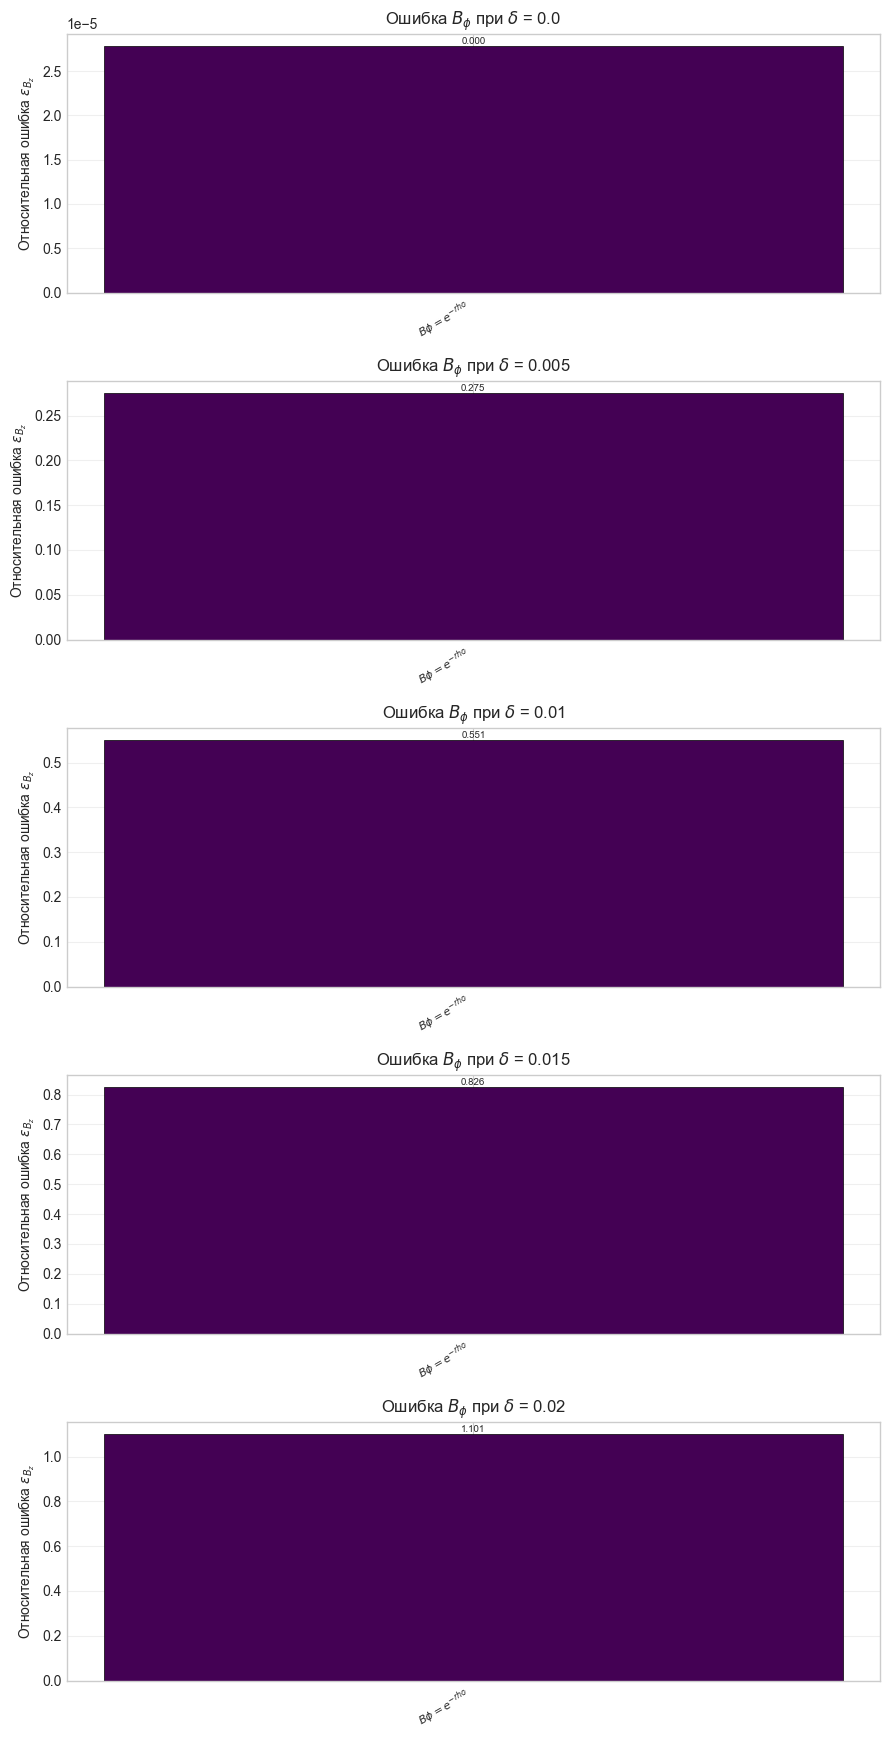

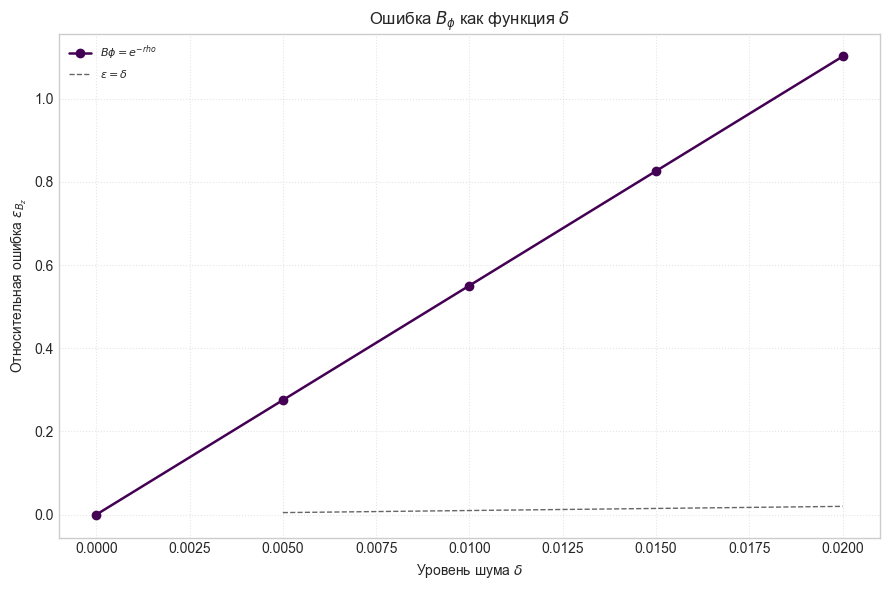

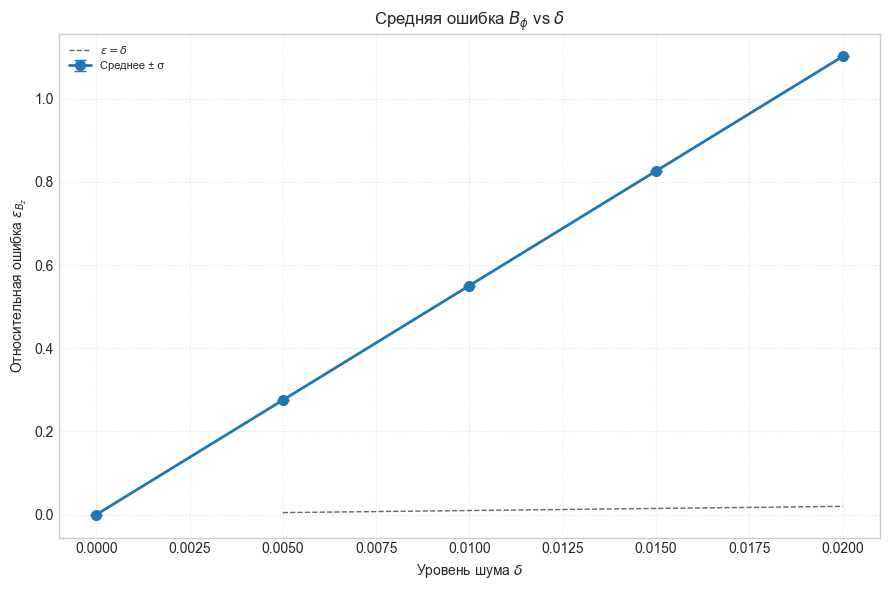


СОХРАНЕНИЕ СВОДНЫХ ТАБЛИЦ
Таблица для B_z:


,delta,run,err_Bz_mean
3,0.000,Bz_constant,2.892082e-11
0,0.000,Bz = $(B0=0.1)$ \rho^2,3.819006e-06
2,0.000,Bz = $e^{-\rho^2}$,8.162139e-04
1,0.000,Bz = $\rho^2 e^{-\rho^2}$,1.023641e-03
6,0.005,Bz = $e^{-\rho^2}$,3.081041e-02
5,0.005,Bz = $\rho^2 e^{-\rho^2}$,4.836273e-02
7,0.005,Bz_constant,9.220455e-02
4,0.005,Bz = $(B0=0.1)$ \rho^2,9.666818e-02
10,0.010,Bz = $e^{-\rho^2}$,5.744727e-02
9,0.010,Bz = $\rho^2 e^{-\rho^2}$,8.552520e-02



Таблица для B_phi:


,delta,run,err_Bphi_mean
0,0.000,$B\phi = e^{-rho}$,0.000028
1,0.005,$B\phi = e^{-rho}$,0.275324
2,0.010,$B\phi = e^{-rho}$,0.550647
3,0.015,$B\phi = e^{-rho}$,0.825970
4,0.020,$B\phi = e^{-rho}$,1.101294


In [ ]:
# ==============================================================================
# СВОДНЫЕ ГРАФИКИ ОШИБОК + ЗАВИСИМОСТЬ ОТ δ
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from methods import load_runs, plot_all_errors_bar, plot_error_vs_noise


# ==============================================================================
# БЛОК 1: АНАЛИЗ ОШИБОК ДЛЯ B_z
# ==============================================================================
print("\n" + "="*50)
print("АНАЛИЗ ОШИБОК ДЛЯ B_z")
print("="*50)
deltas_plot = deltas #[0, 0.005, 0.01, 0.02, 0.03, 0.04]

csv_paths_bz = {d: _fname(d, REG_KIND) for d in deltas_plot}

fl_LOGLOG = False

# --- 1) Столбчатые диаграммы для каждого δ ---
fig, axes = plt.subplots(len(deltas_plot), 1, figsize=(9, 3.5 * len(deltas_plot)))
if len(deltas_plot) == 1: axes = [axes]

for ax, d in zip(axes, deltas_plot):
    f = csv_paths_bz[d]
    if not os.path.exists(f):
        ax.axis('off'); ax.set_title(rf"$\delta$={d} — нет файла"); continue
        
    rho, runs = load_runs(f)
    runs = dict(sorted(runs.items()))  
    plot_all_errors_bar(rho, runs, err_key='err_Bz',
                        title=rf"Ошибка $B_z$ при $\delta$ = {d}", ax=ax)
plt.tight_layout(); plt.show()

# --- 2) Ошибка vs δ: по кривой на каждый run ---
fig, ax = plt.subplots(figsize=(9, 6))
plot_error_vs_noise(csv_paths_bz, deltas_plot, err_key='err_Bz',
                    title=r"Ошибка $B_z$ как функция $\delta$",
                    ax=ax, loglog=fl_LOGLOG, annotate_runs=True)
plt.tight_layout(); plt.show()

# --- 3) Ошибка vs δ: усреднение по запускам ± σ ---
fig, ax = plt.subplots(figsize=(9, 6))
plot_error_vs_noise(csv_paths_bz, deltas_plot, err_key='err_Bz',
                    title=r"Средняя ошибка $B_z$ vs $\delta$",
                    ax=ax, loglog=fl_LOGLOG, annotate_runs=False)
plt.tight_layout(); plt.show()




# ==============================================================================
# БЛОК 3: ЧИСЛЕННАЯ СВОДКА (ТАБЛИЦЫ)
# ==============================================================================
print("\n" + "="*50)
print("СОХРАНЕНИЕ СВОДНЫХ ТАБЛИЦ")
print("="*50)

# --- Таблица для B_z ---
rows_bz = []
for d in deltas_plot:
    f = csv_paths_bz[d]
    if not os.path.exists(f): continue
    _, runs = load_runs(f)
    for name, data in runs.items():
        if 'err_Bz' in data:
            rows_bz.append({'delta': d, 'run': name,
                            'err_Bz_mean': float(np.mean(np.atleast_1d(data['err_Bz'])))})
            
if rows_bz:
    df_err_bz = pd.DataFrame(rows_bz).sort_values(['delta', 'err_Bz_mean'])
    df_err_bz.to_csv(os.path.join(RESULTS_DIR, "summary_errors_Bz.csv"), index=False)
    print("Таблица для B_z:")
    display(df_err_bz)

# --- Таблица для B_phi ---
rows_bphi = []
for d in deltas_plot:
    f = csv_paths_bphi[d]
    if not os.path.exists(f): continue
    _, runs = load_runs(f)
    for name, data in runs.items():
        if 'err_Bphi' in data:
            rows_bphi.append({'delta': d, 'run': name,
                              'err_Bphi_mean': float(np.mean(np.atleast_1d(data['err_Bphi'])))})
            
if rows_bphi:
    df_err_bphi = pd.DataFrame(rows_bphi).sort_values(['delta', 'err_Bphi_mean'])
    df_err_bphi.to_csv(os.path.join(RESULTS_DIR, "summary_errors_Bphi.csv"), index=False)
    print("\nТаблица для B_phi:")
    display(df_err_bphi)


#### ==============================================================================
#### БЛОК 2: АНАЛИЗ ОШИБОК ДЛЯ B_phi
#### ==============================================================================


АНАЛИЗ ОШИБОК ДЛЯ B_phi


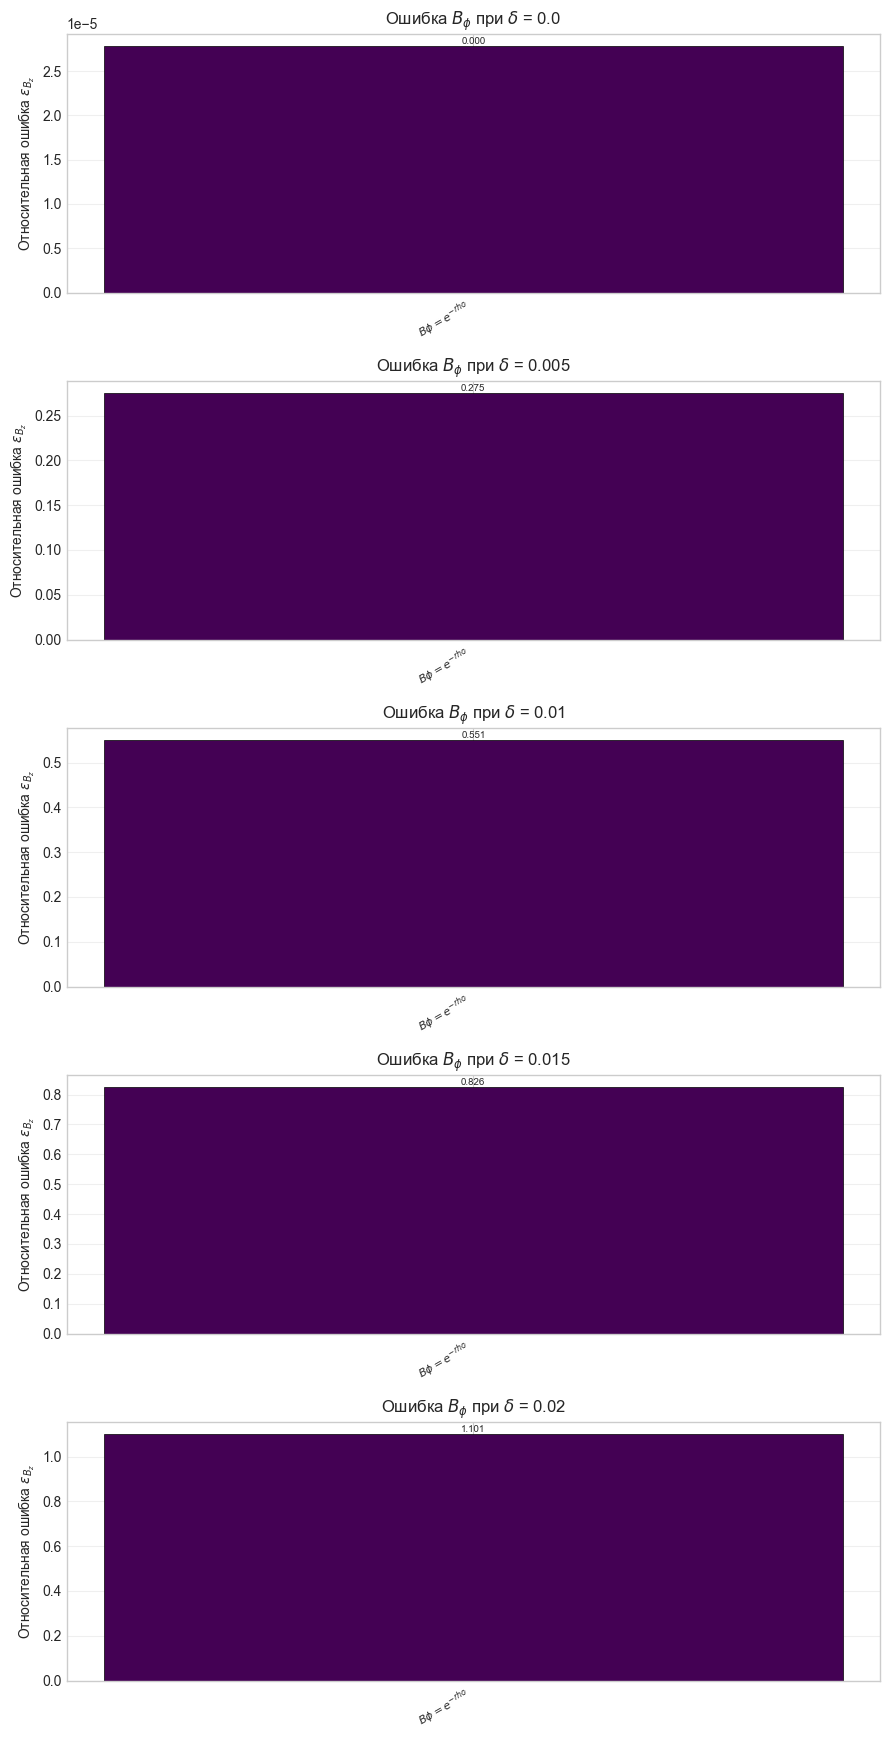

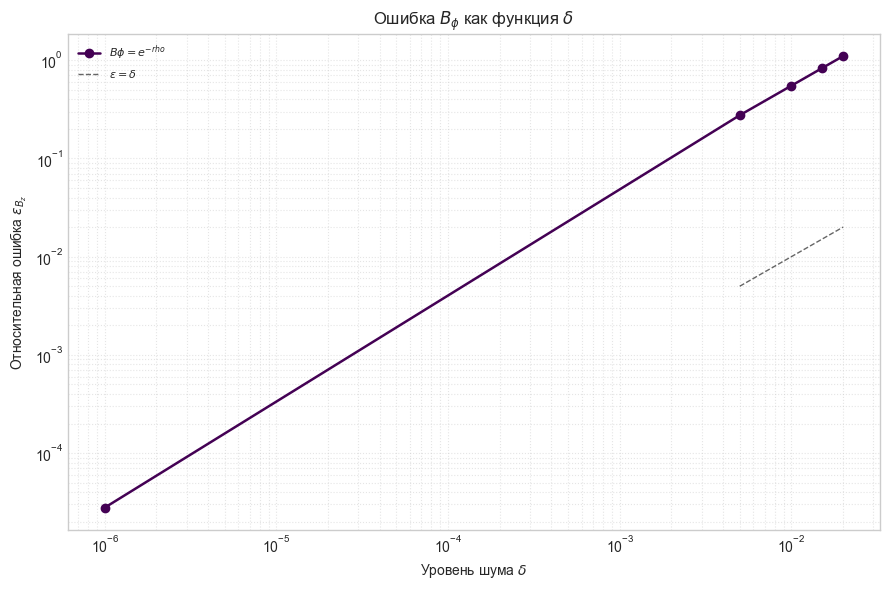

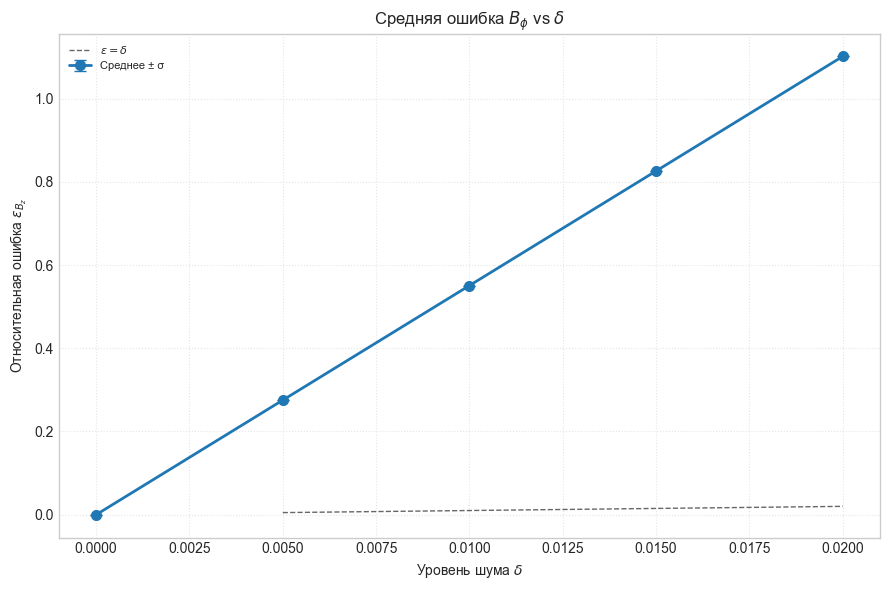

In [21]:

print("\n" + "="*50)
print("АНАЛИЗ ОШИБОК ДЛЯ B_phi")
print("="*50)
deltas_plot = [0.0, 0.005, 0.01, 0.015, 0.02]

csv_paths_bphi = {d: _fname(d, REG_KIND, 'Bphi', '_(rho)_(var_B)') for d in deltas_plot}

fl_LOGLOG = True

# Проверяем, есть ли хотя бы один файл для B_phi
if any(os.path.exists(f) for f in csv_paths_bphi.values()):
    # --- 1) Столбчатые диаграммы для каждого δ ---
    fig, axes = plt.subplots(len(deltas_plot), 1, figsize=(9, 3.5 * len(deltas_plot)))
    if len(deltas_plot) == 1: axes = [axes]

    for ax, d in zip(axes, deltas_plot):
        f = csv_paths_bphi[d]
        if not os.path.exists(f):
            ax.axis('off'); ax.set_title(rf"$\delta$={d} — нет файла"); continue
            
        rho, runs = load_runs(f)
        runs = dict(sorted(runs.items()))  
        plot_all_errors_bar(rho, runs, err_key='err_Bphi',
                            title=rf"Ошибка $B_\phi$ при $\delta$ = {d}", ax=ax)
    plt.tight_layout(); plt.show()

    # --- 2) Ошибка vs δ: по кривой на каждый run ---
    fig, ax = plt.subplots(figsize=(9, 6))
    plot_error_vs_noise(csv_paths_bphi, deltas_plot, err_key='err_Bphi',
                        title=r"Ошибка $B_\phi$ как функция $\delta$",
                        ax=ax, loglog=fl_LOGLOG, annotate_runs=True)
    plt.tight_layout(); plt.show()

    # --- 3) Ошибка vs δ: усреднение по запускам ± σ ---
    fig, ax = plt.subplots(figsize=(9, 6))
    plot_error_vs_noise(csv_paths_bphi, deltas_plot, err_key='err_Bphi',
                        title=r"Средняя ошибка $B_\phi$ vs $\delta$",
                        ax=ax, loglog=fl_LOGLOG, annotate_runs=False)
    plt.tight_layout(); plt.show()
else:
    print("⚠️ Файлы для B_phi не найдены. Пропускаем графики.")